# Part I - Police Crime Statistics 2025 (Germany)
## by Oliver Maerz

## Introduction

This notebook looks at 2025 German police crime statistics (PKS 2025) from the BKA (Federal Criminal Police Office): suspects by offence group and nationality. Absolute counts alone can be misleading when population sizes differ a lot, so I also bring in Destatis population by citizenship to compare rates per 100,000. The youngest Destatis age band is approximated so the totals better match the BKA figures (age 8+, not 6+).

Questions I want to answer:
- Which nationalities dominate absolute suspect counts (including Germany)?
- How do those same groups look once expressed as suspects per 100k?
- Does that picture change across a few selected aggregate offence groups (e.g. theft, violent crime, offences against life)?


## Preliminary Wrangling

In [246]:
# import all packages and set plots to be embedded inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl # for excel files
import os # to check if data files exist
import requests # to download data files


### Settings


In [247]:
# year to analyze
YEAR = 2025
# overall crime excluding residence/asylum/free-movement is the key 890000
OVERALL_KEY = '890000'   
# top nationalities by absolute suspects for bi/multi plots
TOP_N = 15
# number of non-German nationalities for the histogram               
HIST_TOP_N = 40
# number of nationalities in the clustered multivariate bar chart          
CLUSTER_TOP_N = 5        
# main color to use for plots
PLOT_COLOR = 'orange'
# in cases where we need a second color
SECONDARY_COLOR = 'steelblue'


### Download the data 
... (in case it is not already in the data folder)

> Note: The population data file (Destatis 12411-0009_en.csv) from the "Statistisches Bundesamt" needs to be downloaded manually and copied into the data folder [via this URL](https://genesis.destatis.de/datenbank/online/statistic/12411/table/12411-0009/table-toolbar/search/s/JTIyY2l0aXplbnNoaXAlMjI%3D#filter=JTdCJTIyaGlkZUVtcHR5Q29scyUyMiUzQWZhbHNlJTJDJTIyaGlkZUVtcHR5Um93cyUyMiUzQWZhbHNlJTJDJTIyY2FwdGlvbiUyMiUzQSU1QiU3QiUyMnZhcmlhYmxlSWQlMjIlM0ElMjIxMjQxMSUyMiUyQyUyMmlkJTIyJTNBJTIyZmlsdGVyLjAlMjIlMkMlMjJ2YWx1ZXNJZHMlMjIlM0ElNUIlMjIxMjQxMSUyMiU1RCUyQyUyMmNoaWxkcmVuJTIyJTNBJTVCJTdCJTIydmFyaWFibGVJZCUyMiUzQSUyMkRJTlNHJTIyJTJDJTIyaWQlMjIlM0ElMjJmaWx0ZXIuMC4wJTIyJTJDJTIydmFsdWVzSWRzJTIyJTNBJTVCJTIyREclMjIlNUQlMkMlMjJjaGlsZHJlbiUyMiUzQSU1QiU3QiUyMnZhcmlhYmxlSWQlMjIlM0ElMjJCRVZTVEQlMjIlMkMlMjJpZCUyMiUzQSUyMmZpbHRlci4wLjAuMCUyMiUyQyUyMnZhbHVlc0lkcyUyMiUzQSU1QiUyMlFNVSUyMiU1RCUyQyUyMmNoaWxkcmVuJTIyJTNBJTVCJTVEJTJDJTIyc2hvd0FzSW50ZXJsaW5lJTIyJTNBZmFsc2UlMkMlMjJpc0hpZGRlbiUyMiUzQWZhbHNlJTJDJTIyYmxvY2tDb2RlJTIyJTNBJTIyYzElMjIlMkMlMjJwb3NzaWJsZVBsYWNlcyUyMiUzQSU1QiU1RCU3RCU1RCUyQyUyMnNob3dBc0ludGVybGluZSUyMiUzQWZhbHNlJTJDJTIyc2hvd1ZhcmlhYmxlJTIyJTNBZmFsc2UlMkMlMjJzaG93VmFyaWFibGVWYWx1ZSUyMiUzQSU1QiUyMkxBQkVMJTIyJTVEJTJDJTIyc29ydCUyMiUzQSUyMkNvZGVBc2MlMjIlMkMlMjJpc0hpZGRlbiUyMiUzQWZhbHNlJTJDJTIyYmxvY2tDb2RlJTIyJTNBJTIydjElMjIlMkMlMjJwb3NzaWJsZVBsYWNlcyUyMiUzQSU1QiU1RCU3RCU1RCUyQyUyMnNob3dBc0ludGVybGluZSUyMiUzQWZhbHNlJTJDJTIyaXNIaWRkZW4lMjIlM0FmYWxzZSUyQyUyMmJsb2NrQ29kZSUyMiUzQSUyMnMxJTIyJTJDJTIycG9zc2libGVQbGFjZXMlMjIlM0ElNUIlNUQlN0QlNUQlMkMlMjJyb3dIZWFkZXIlMjIlM0ElNUIlN0IlMjJ2YXJpYWJsZUlkJTIyJTNBJTIyU1RBRyUyMiUyQyUyMmlkJTIyJTNBJTIycm93VGl0bGUuMCUyMiUyQyUyMnZhbHVlc0lkcyUyMiUzQSU1QiUyMjIwMjQtMTItMzElMjIlNUQlMkMlMjJjaGlsZHJlbiUyMiUzQSU1QiU3QiUyMnZhcmlhYmxlSWQlMjIlM0ElMjJTVEFBRzklMjIlMkMlMjJpZCUyMiUzQSUyMnJvd1RpdGxlLjAuMCUyMiUyQyUyMnZhbHVlc0lkcyUyMiUzQSU1QiUyMkRHJTIyJTJDJTIyU1QxMjElMjIlMkMlMjJTVDEyMiUyMiUyQyUyMlNUMTI0JTIyJTJDJTIyU1QxMjUlMjIlMkMlMjJTVDEyNiUyMiUyQyUyMlNUMTI3JTIyJTJDJTIyU1QxMjglMjIlMkMlMjJTVDEyOSUyMiUyQyUyMlNUMTMwJTIyJTJDJTIyU1QxMzElMjIlMkMlMjJTVDEzNCUyMiUyQyUyMlNUMTM1JTIyJTJDJTIyU1QxMzYlMjIlMkMlMjJTVDEzNyUyMiUyQyUyMlNUMTM5JTIyJTJDJTIyU1QxNDAlMjIlMkMlMjJTVDE0MiUyMiUyQyUyMlNUMTQzJTIyJTJDJTIyU1QxNDQlMjIlMkMlMjJTVDE0NSUyMiUyQyUyMlNUMTQ2JTIyJTJDJTIyU1QxNDglMjIlMkMlMjJTVDE0OSUyMiUyQyUyMlNUMTUwJTIyJTJDJTIyU1QxNTElMjIlMkMlMjJTVDE1MiUyMiUyQyUyMlNUMTUzJTIyJTJDJTIyU1QxNTQlMjIlMkMlMjJTVDE1NSUyMiUyQyUyMlNUMTU3JTIyJTJDJTIyU1QxNTglMjIlMkMlMjJTVDE2MCUyMiUyQyUyMlNUMTYxJTIyJTJDJTIyU1QxNjMlMjIlMkMlMjJTVDE2NCUyMiUyQyUyMlNUMTY1JTIyJTJDJTIyU1QxNjYlMjIlMkMlMjJTVDE2OCUyMiUyQyUyMlNUMTY5JTIyJTJDJTIyU1QxNzAlMjIlMkMlMjJTVDE4MSUyMiUyQyUyMlNUMTk5JTIyJTJDJTIyU1QyMjElMjIlMkMlMjJTVDIyMyUyMiUyQyUyMlNUMjI0JTIyJTJDJTIyU1QyMjUlMjIlMkMlMjJTVDIyOSUyMiUyQyUyMlNUMjMxJTIyJTJDJTIyU1QyMzIlMjIlMkMlMjJTVDIzNyUyMiUyQyUyMlNUMjM4JTIyJTJDJTIyU1QyNDMlMjIlMkMlMjJTVDI0OCUyMiUyQyUyMlNUMjQ5JTIyJTJDJTIyU1QyNTElMjIlMkMlMjJTVDI1MiUyMiUyQyUyMlNUMjU4JTIyJTJDJTIyU1QyNTklMjIlMkMlMjJTVDI2MSUyMiUyQyUyMlNUMjYyJTIyJTJDJTIyU1QyNjMlMjIlMkMlMjJTVDI2OSUyMiUyQyUyMlNUMjcyJTIyJTJDJTIyU1QyNzMlMjIlMkMlMjJTVDI3NiUyMiUyQyUyMlNUMjc3JTIyJTJDJTIyU1QyNzglMjIlMkMlMjJTVDI4MyUyMiUyQyUyMlNUMjg1JTIyJTJDJTIyU1QyODclMjIlMkMlMjJTVDI5OSUyMiUyQyUyMlNUMzIzJTIyJTJDJTIyU1QzMjclMjIlMkMlMjJTVDMzMiUyMiUyQyUyMlNUMzM1JTIyJTJDJTIyU1QzMzYlMjIlMkMlMjJTVDM0OCUyMiUyQyUyMlNUMzQ5JTIyJTJDJTIyU1QzNTElMjIlMkMlMjJTVDM1MyUyMiUyQyUyMlNUMzYxJTIyJTJDJTIyU1QzNjclMjIlMkMlMjJTVDM2OCUyMiUyQyUyMlNUMzk5JTIyJTJDJTIyU1Q0MjElMjIlMkMlMjJTVDQyMiUyMiUyQyUyMlNUNDIzJTIyJTJDJTIyU1Q0MjUlMjIlMkMlMjJTVDQzMCUyMiUyQyUyMlNUNDMxJTIyJTJDJTIyU1Q0MzIlMjIlMkMlMjJTVDQzNCUyMiUyQyUyMlNUNDM2JTIyJTJDJTIyU1Q0MzclMjIlMkMlMjJTVDQzOCUyMiUyQyUyMlNUNDM5JTIyJTJDJTIyU1Q0NDElMjIlMkMlMjJTVDQ0MiUyMiUyQyUyMlNUNDQ0JTIyJTJDJTIyU1Q0NDUlMjIlMkMlMjJTVDQ0OCUyMiUyQyUyMlNUNDUwJTIyJTJDJTIyU1Q0NTElMjIlMkMlMjJTVDQ1NyUyMiUyQyUyMlNUNDU4JTIyJTJDJTIyU1Q0NTklMjIlMkMlMjJTVDQ2MCUyMiUyQyUyMlNUNDYxJTIyJTJDJTIyU1Q0NjIlMjIlMkMlMjJTVDQ2NSUyMiUyQyUyMlNUNDY3JTIyJTJDJTIyU1Q0NjklMjIlMkMlMjJTVDQ3MCUyMiUyQyUyMlNUNDcyJTIyJTJDJTIyU1Q0NzQlMjIlMkMlMjJTVDQ3NSUyMiUyQyUyMlNUNDc2JTIyJTJDJTIyU1Q0NzclMjIlMkMlMjJTVDQ3OSUyMiUyQyUyMlNUNDgyJTIyJTJDJTIyU1Q0OTklMjIlMkMlMjJTVDUyMyUyMiUyQyUyMlNUNTM2JTIyJTJDJTIyU1Q1OTVCJTIyJTJDJTIyU1Q5OTclMjIlMkMlMjJTVEFBVDkwMCUyMiU1RCUyQyUyMmNoaWxkcmVuJTIyJTNBJTVCJTVEJTJDJTIyc2hvd0FzSW50ZXJsaW5lJTIyJTNBZmFsc2UlMkMlMjJzaG93VmFyaWFibGUlMjIlM0F0cnVlJTJDJTIyc2hvd1ZhcmlhYmxlVmFsdWUlMjIlM0ElNUIlMjJMQUJFTCUyMiU1RCUyQyUyMmlzSGlkZGVuJTIyJTNBZmFsc2UlMkMlMjJibG9ja0NvZGUlMjIlM0ElMjJ2NSUyMiUyQyUyMnBvc3NpYmxlUGxhY2VzJTIyJTNBJTVCJTdCJTIycHJldlBhcmVudCUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnYyJTIyJTJDJTIyaWQlMjIlM0ElMjJyb3dUaXRsZS4wJTIyJTdEJTJDJTIyZWxlbWVudEFib3ZlJTIyJTNBbnVsbCUyQyUyMmVsZW1lbnRCZWxvdyUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnYzJTIyJTJDJTIyaWQlMjIlM0ElMjJjb2xUaXRsZS4wJTIyJTdEJTJDJTIybmV3U2libGluZ0luZGV4JTIyJTNBMCUyQyUyMmhhc1RyYW5zcG9zZVBhcnQlMjIlM0F0cnVlJTdEJTJDJTdCJTIycHJldlBhcmVudCUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnYyJTIyJTJDJTIyaWQlMjIlM0ElMjJyb3dUaXRsZS4wJTIyJTdEJTJDJTIybmV3UGFyZW50JTIyJTNBJTdCJTIyYmxvY2tDb2RlJTIyJTNBJTIydjMlMjIlMkMlMjJpZCUyMiUzQSUyMmNvbFRpdGxlLjAlMjIlN0QlMkMlMjJlbGVtZW50QWJvdmUlMjIlM0ElN0IlMjJibG9ja0NvZGUlMjIlM0ElMjJ2MyUyMiUyQyUyMmlkJTIyJTNBJTIyY29sVGl0bGUuMCUyMiU3RCUyQyUyMmVsZW1lbnRCZWxvdyUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnY0JTIyJTJDJTIyaWQlMjIlM0ElMjJjb2xUaXRsZS4wLjAlMjIlN0QlMkMlMjJuZXdTaWJsaW5nSW5kZXglMjIlM0EwJTJDJTIyaGFzVHJhbnNwb3NlUGFydCUyMiUzQXRydWUlN0QlMkMlN0IlMjJwcmV2UGFyZW50JTIyJTNBJTdCJTIyYmxvY2tDb2RlJTIyJTNBJTIydjIlMjIlMkMlMjJpZCUyMiUzQSUyMnJvd1RpdGxlLjAlMjIlN0QlMkMlMjJuZXdQYXJlbnQlMjIlM0ElN0IlMjJibG9ja0NvZGUlMjIlM0ElMjJ2NCUyMiUyQyUyMmlkJTIyJTNBJTIyY29sVGl0bGUuMC4wJTIyJTdEJTJDJTIyZWxlbWVudEFib3ZlJTIyJTNBJTdCJTIyYmxvY2tDb2RlJTIyJTNBJTIydjQlMjIlMkMlMjJpZCUyMiUzQSUyMmNvbFRpdGxlLjAuMCUyMiU3RCUyQyUyMmVsZW1lbnRCZWxvdyUyMiUzQW51bGwlMkMlMjJuZXdTaWJsaW5nSW5kZXglMjIlM0EwJTJDJTIyaGFzVHJhbnNwb3NlUGFydCUyMiUzQXRydWUlN0QlNUQlN0QlNUQlMkMlMjJzaG93QXNJbnRlcmxpbmUlMjIlM0F0cnVlJTJDJTIyc2hvd1ZhcmlhYmxlJTIyJTNBdHJ1ZSUyQyUyMnNob3dWYXJpYWJsZVZhbHVlJTIyJTNBJTVCJTIyTEFCRUwlMjIlNUQlMkMlMjJpc0hpZGRlbiUyMiUzQWZhbHNlJTJDJTIyYmxvY2tDb2RlJTIyJTNBJTIydjIlMjIlMkMlMjJwb3NzaWJsZVBsYWNlcyUyMiUzQSU1QiU1RCU3RCU1RCUyQyUyMmNvbHVtbkhlYWRlciUyMiUzQSU1QiU3QiUyMnZhcmlhYmxlSWQlMjIlM0ElMjJHRVMlMjIlMkMlMjJpZCUyMiUzQSUyMmNvbFRpdGxlLjAlMjIlMkMlMjJ2YWx1ZXNJZHMlMjIlM0ElNUIlMjJHRVNNJTIyJTJDJTIyJTI1VE9UQUwlMjUlMjIlMkMlMjJHRVNXJTIyJTVEJTJDJTIyY2hpbGRyZW4lMjIlM0ElNUIlN0IlMjJ2YXJpYWJsZUlkJTIyJTNBJTIyQUxUMDMxJTIyJTJDJTIyaWQlMjIlM0ElMjJjb2xUaXRsZS4wLjAlMjIlMkMlMjJ2YWx1ZXNJZHMlMjIlM0ElNUIlMjJBTFQwMDZCMTAlMjIlMkMlMjJBTFQwMTBCMTUlMjIlMkMlMjJBTFQwMTVCMTglMjIlMkMlMjJBTFQwMThCMjElMjIlMkMlMjJBTFQwMjFCMzAlMjIlMkMlMjJBTFQwMzBCNTAlMjIlMkMlMjJBTFQwNTBCNjAlMjIlMkMlMjJBTFQwNjBCNjUlMjIlMkMlMjJBTFQwNjVVTSUyMiUyQyUyMiUyNVRPVEFMJTI1JTIyJTVEJTJDJTIyY2hpbGRyZW4lMjIlM0ElNUIlNUQlMkMlMjJzaG93QXNJbnRlcmxpbmUlMjIlM0FmYWxzZSUyQyUyMnNob3dWYXJpYWJsZSUyMiUzQWZhbHNlJTJDJTIyc2hvd1ZhcmlhYmxlVmFsdWUlMjIlM0ElNUIlMjJMQUJFTCUyMiU1RCUyQyUyMmlzSGlkZGVuJTIyJTNBZmFsc2UlMkMlMjJibG9ja0NvZGUlMjIlM0ElMjJ2NCUyMiUyQyUyMnBvc3NpYmxlUGxhY2VzJTIyJTNBJTVCJTdCJTIycHJldlBhcmVudCUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnYzJTIyJTJDJTIyaWQlMjIlM0ElMjJjb2xUaXRsZS4wJTIyJTdEJTJDJTIyZWxlbWVudEFib3ZlJTIyJTNBbnVsbCUyQyUyMmVsZW1lbnRCZWxvdyUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnYzJTIyJTJDJTIyaWQlMjIlM0ElMjJjb2xUaXRsZS4wJTIyJTdEJTJDJTIybmV3U2libGluZ0luZGV4JTIyJTNBMCUyQyUyMmhhc1RyYW5zcG9zZVBhcnQlMjIlM0FmYWxzZSU3RCUyQyU3QiUyMnByZXZQYXJlbnQlMjIlM0ElN0IlMjJibG9ja0NvZGUlMjIlM0ElMjJ2MyUyMiUyQyUyMmlkJTIyJTNBJTIyY29sVGl0bGUuMCUyMiU3RCUyQyUyMm5ld1BhcmVudCUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnYyJTIyJTJDJTIyaWQlMjIlM0ElMjJyb3dUaXRsZS4wJTIyJTdEJTJDJTIyZWxlbWVudEFib3ZlJTIyJTNBJTdCJTIyYmxvY2tDb2RlJTIyJTNBJTIydjIlMjIlMkMlMjJpZCUyMiUzQSUyMnJvd1RpdGxlLjAlMjIlN0QlMkMlMjJlbGVtZW50QmVsb3clMjIlM0ElN0IlMjJibG9ja0NvZGUlMjIlM0ElMjJ2NSUyMiUyQyUyMmlkJTIyJTNBJTIycm93VGl0bGUuMC4wJTIyJTdEJTJDJTIybmV3U2libGluZ0luZGV4JTIyJTNBMCUyQyUyMmhhc1RyYW5zcG9zZVBhcnQlMjIlM0F0cnVlJTdEJTJDJTdCJTIycHJldlBhcmVudCUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnYzJTIyJTJDJTIyaWQlMjIlM0ElMjJjb2xUaXRsZS4wJTIyJTdEJTJDJTIybmV3UGFyZW50JTIyJTNBJTdCJTIyYmxvY2tDb2RlJTIyJTNBJTIydjUlMjIlMkMlMjJpZCUyMiUzQSUyMnJvd1RpdGxlLjAuMCUyMiU3RCUyQyUyMmVsZW1lbnRBYm92ZSUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnY1JTIyJTJDJTIyaWQlMjIlM0ElMjJyb3dUaXRsZS4wLjAlMjIlN0QlMkMlMjJlbGVtZW50QmVsb3clMjIlM0FudWxsJTJDJTIybmV3U2libGluZ0luZGV4JTIyJTNBMCUyQyUyMmhhc1RyYW5zcG9zZVBhcnQlMjIlM0F0cnVlJTdEJTVEJTdEJTVEJTJDJTIyc2hvd0FzSW50ZXJsaW5lJTIyJTNBZmFsc2UlMkMlMjJzaG93VmFyaWFibGUlMjIlM0FmYWxzZSUyQyUyMnNob3dWYXJpYWJsZVZhbHVlJTIyJTNBJTVCJTIyTEFCRUwlMjIlNUQlMkMlMjJpc0hpZGRlbiUyMiUzQWZhbHNlJTJDJTIyYmxvY2tDb2RlJTIyJTNBJTIydjMlMjIlMkMlMjJwb3NzaWJsZVBsYWNlcyUyMiUzQSU1QiU3QiUyMm5ld1BhcmVudCUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnY0JTIyJTJDJTIyaWQlMjIlM0ElMjJjb2xUaXRsZS4wLjAlMjIlN0QlMkMlMjJlbGVtZW50QWJvdmUlMjIlM0ElN0IlMjJibG9ja0NvZGUlMjIlM0ElMjJ2NCUyMiUyQyUyMmlkJTIyJTNBJTIyY29sVGl0bGUuMC4wJTIyJTdEJTJDJTIyZWxlbWVudEJlbG93JTIyJTNBbnVsbCUyQyUyMm5ld1NpYmxpbmdJbmRleCUyMiUzQTAlMkMlMjJoYXNUcmFuc3Bvc2VQYXJ0JTIyJTNBZmFsc2UlN0QlMkMlN0IlMjJuZXdQYXJlbnQlMjIlM0ElN0IlMjJibG9ja0NvZGUlMjIlM0ElMjJ2MiUyMiUyQyUyMmlkJTIyJTNBJTIycm93VGl0bGUuMCUyMiU3RCUyQyUyMmVsZW1lbnRBYm92ZSUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnYyJTIyJTJDJTIyaWQlMjIlM0ElMjJyb3dUaXRsZS4wJTIyJTdEJTJDJTIyZWxlbWVudEJlbG93JTIyJTNBJTdCJTIyYmxvY2tDb2RlJTIyJTNBJTIydjUlMjIlMkMlMjJpZCUyMiUzQSUyMnJvd1RpdGxlLjAuMCUyMiU3RCUyQyUyMm5ld1NpYmxpbmdJbmRleCUyMiUzQTAlMkMlMjJoYXNUcmFuc3Bvc2VQYXJ0JTIyJTNBdHJ1ZSU3RCUyQyU3QiUyMm5ld1BhcmVudCUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnY1JTIyJTJDJTIyaWQlMjIlM0ElMjJyb3dUaXRsZS4wLjAlMjIlN0QlMkMlMjJlbGVtZW50QWJvdmUlMjIlM0ElN0IlMjJibG9ja0NvZGUlMjIlM0ElMjJ2NSUyMiUyQyUyMmlkJTIyJTNBJTIycm93VGl0bGUuMC4wJTIyJTdEJTJDJTIyZWxlbWVudEJlbG93JTIyJTNBbnVsbCUyQyUyMm5ld1NpYmxpbmdJbmRleCUyMiUzQTAlMkMlMjJoYXNUcmFuc3Bvc2VQYXJ0JTIyJTNBdHJ1ZSU3RCU1RCU3RCU1RCUyQyUyMmZpeEZpcnN0Q29sdW1ucyUyMiUzQWZhbHNlJTdE&sortByValue=default). Make sure to **uncheck** the "Include quality symbols" checkbox on the download diaglog of the Destatis website. 

In [248]:
# The file names below are for the year defined in the YEAR variable. The base url may be in a different format for some years, so double check. 

files = []
download_urls = []
url_suffix = '?__blob=publicationFile'

# Population data
destatis_file = '12411-0009_en.csv' # this needs to be downloaded manually 

# Population data check (to verify the destatis file data matches the BKA data as close as possible)
pop_url = f'https://www.bka.de/SharedDocs/Downloads/DE/Publikationen/PolizeilicheKriminalstatistik/{YEAR}/Sonst_Tabellen/'

pop_not_german_file = '01-BU-BV-TVBZ-ndeu-ab-2009_xls.xlsx'
download_urls.append(pop_url + pop_not_german_file + url_suffix)
files.append(pop_not_german_file)

pop_german_file = '01-BU-BV-TVBZ-deu-ab-2009_xls.xlsx'
download_urls.append(pop_url + pop_german_file + url_suffix)
files.append(pop_german_file)


# Nationalities of suspects
nationalities_file = 'BU-TV-22-T62-TV-Staatsangehoerigkeiten_xls.xlsx'
nationalities_url = f'https://www.bka.de/SharedDocs/Downloads/DE/Publikationen/PolizeilicheKriminalstatistik/{YEAR}/Bund/Tatverdaechtige/'

download_urls.append(nationalities_url + nationalities_file + url_suffix)
files.append(nationalities_file)


os.makedirs('./data', exist_ok=True)
for filename, url in zip(files, download_urls):
    dest = os.path.join('./data', filename)
    if os.path.exists(dest):
        continue

    try:
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        with open(dest, 'wb') as f:
            f.write(response.content)
    except requests.exceptions.RequestException as e:
            print(f'Download failed for {filename}. Please check the filename and try again.')

In [249]:
# check if the Destatis data file is present
if not os.path.exists(f'./data/{destatis_file}'):
    print(f'ERROR: The Destatis data file {destatis_file} is missing! Please download this website:')
    print('https://genesis.destatis.de/datenbank/online/statistic/12411/table/12411-0009/table-toolbar/search/s/JTIyY2l0aXplbnNoaXAlMjI%3D#filter=JTdCJTIyaGlkZUVtcHR5Q29scyUyMiUzQWZhbHNlJTJDJTIyaGlkZUVtcHR5Um93cyUyMiUzQWZhbHNlJTJDJTIyY2FwdGlvbiUyMiUzQSU1QiU3QiUyMnZhcmlhYmxlSWQlMjIlM0ElMjIxMjQxMSUyMiUyQyUyMmlkJTIyJTNBJTIyZmlsdGVyLjAlMjIlMkMlMjJ2YWx1ZXNJZHMlMjIlM0ElNUIlMjIxMjQxMSUyMiU1RCUyQyUyMmNoaWxkcmVuJTIyJTNBJTVCJTdCJTIydmFyaWFibGVJZCUyMiUzQSUyMkRJTlNHJTIyJTJDJTIyaWQlMjIlM0ElMjJmaWx0ZXIuMC4wJTIyJTJDJTIydmFsdWVzSWRzJTIyJTNBJTVCJTIyREclMjIlNUQlMkMlMjJjaGlsZHJlbiUyMiUzQSU1QiU3QiUyMnZhcmlhYmxlSWQlMjIlM0ElMjJCRVZTVEQlMjIlMkMlMjJpZCUyMiUzQSUyMmZpbHRlci4wLjAuMCUyMiUyQyUyMnZhbHVlc0lkcyUyMiUzQSU1QiUyMlFNVSUyMiU1RCUyQyUyMmNoaWxkcmVuJTIyJTNBJTVCJTVEJTJDJTIyc2hvd0FzSW50ZXJsaW5lJTIyJTNBZmFsc2UlMkMlMjJpc0hpZGRlbiUyMiUzQWZhbHNlJTJDJTIyYmxvY2tDb2RlJTIyJTNBJTIyYzElMjIlMkMlMjJwb3NzaWJsZVBsYWNlcyUyMiUzQSU1QiU1RCU3RCU1RCUyQyUyMnNob3dBc0ludGVybGluZSUyMiUzQWZhbHNlJTJDJTIyc2hvd1ZhcmlhYmxlJTIyJTNBZmFsc2UlMkMlMjJzaG93VmFyaWFibGVWYWx1ZSUyMiUzQSU1QiUyMkxBQkVMJTIyJTVEJTJDJTIyc29ydCUyMiUzQSUyMkNvZGVBc2MlMjIlMkMlMjJpc0hpZGRlbiUyMiUzQWZhbHNlJTJDJTIyYmxvY2tDb2RlJTIyJTNBJTIydjElMjIlMkMlMjJwb3NzaWJsZVBsYWNlcyUyMiUzQSU1QiU1RCU3RCU1RCUyQyUyMnNob3dBc0ludGVybGluZSUyMiUzQWZhbHNlJTJDJTIyaXNIaWRkZW4lMjIlM0FmYWxzZSUyQyUyMmJsb2NrQ29kZSUyMiUzQSUyMnMxJTIyJTJDJTIycG9zc2libGVQbGFjZXMlMjIlM0ElNUIlNUQlN0QlNUQlMkMlMjJyb3dIZWFkZXIlMjIlM0ElNUIlN0IlMjJ2YXJpYWJsZUlkJTIyJTNBJTIyU1RBRyUyMiUyQyUyMmlkJTIyJTNBJTIycm93VGl0bGUuMCUyMiUyQyUyMnZhbHVlc0lkcyUyMiUzQSU1QiUyMjIwMjQtMTItMzElMjIlNUQlMkMlMjJjaGlsZHJlbiUyMiUzQSU1QiU3QiUyMnZhcmlhYmxlSWQlMjIlM0ElMjJTVEFBRzklMjIlMkMlMjJpZCUyMiUzQSUyMnJvd1RpdGxlLjAuMCUyMiUyQyUyMnZhbHVlc0lkcyUyMiUzQSU1QiUyMkRHJTIyJTJDJTIyU1QxMjElMjIlMkMlMjJTVDEyMiUyMiUyQyUyMlNUMTI0JTIyJTJDJTIyU1QxMjUlMjIlMkMlMjJTVDEyNiUyMiUyQyUyMlNUMTI3JTIyJTJDJTIyU1QxMjglMjIlMkMlMjJTVDEyOSUyMiUyQyUyMlNUMTMwJTIyJTJDJTIyU1QxMzElMjIlMkMlMjJTVDEzNCUyMiUyQyUyMlNUMTM1JTIyJTJDJTIyU1QxMzYlMjIlMkMlMjJTVDEzNyUyMiUyQyUyMlNUMTM5JTIyJTJDJTIyU1QxNDAlMjIlMkMlMjJTVDE0MiUyMiUyQyUyMlNUMTQzJTIyJTJDJTIyU1QxNDQlMjIlMkMlMjJTVDE0NSUyMiUyQyUyMlNUMTQ2JTIyJTJDJTIyU1QxNDglMjIlMkMlMjJTVDE0OSUyMiUyQyUyMlNUMTUwJTIyJTJDJTIyU1QxNTElMjIlMkMlMjJTVDE1MiUyMiUyQyUyMlNUMTUzJTIyJTJDJTIyU1QxNTQlMjIlMkMlMjJTVDE1NSUyMiUyQyUyMlNUMTU3JTIyJTJDJTIyU1QxNTglMjIlMkMlMjJTVDE2MCUyMiUyQyUyMlNUMTYxJTIyJTJDJTIyU1QxNjMlMjIlMkMlMjJTVDE2NCUyMiUyQyUyMlNUMTY1JTIyJTJDJTIyU1QxNjYlMjIlMkMlMjJTVDE2OCUyMiUyQyUyMlNUMTY5JTIyJTJDJTIyU1QxNzAlMjIlMkMlMjJTVDE4MSUyMiUyQyUyMlNUMTk5JTIyJTJDJTIyU1QyMjElMjIlMkMlMjJTVDIyMyUyMiUyQyUyMlNUMjI0JTIyJTJDJTIyU1QyMjUlMjIlMkMlMjJTVDIyOSUyMiUyQyUyMlNUMjMxJTIyJTJDJTIyU1QyMzIlMjIlMkMlMjJTVDIzNyUyMiUyQyUyMlNUMjM4JTIyJTJDJTIyU1QyNDMlMjIlMkMlMjJTVDI0OCUyMiUyQyUyMlNUMjQ5JTIyJTJDJTIyU1QyNTElMjIlMkMlMjJTVDI1MiUyMiUyQyUyMlNUMjU4JTIyJTJDJTIyU1QyNTklMjIlMkMlMjJTVDI2MSUyMiUyQyUyMlNUMjYyJTIyJTJDJTIyU1QyNjMlMjIlMkMlMjJTVDI2OSUyMiUyQyUyMlNUMjcyJTIyJTJDJTIyU1QyNzMlMjIlMkMlMjJTVDI3NiUyMiUyQyUyMlNUMjc3JTIyJTJDJTIyU1QyNzglMjIlMkMlMjJTVDI4MyUyMiUyQyUyMlNUMjg1JTIyJTJDJTIyU1QyODclMjIlMkMlMjJTVDI5OSUyMiUyQyUyMlNUMzIzJTIyJTJDJTIyU1QzMjclMjIlMkMlMjJTVDMzMiUyMiUyQyUyMlNUMzM1JTIyJTJDJTIyU1QzMzYlMjIlMkMlMjJTVDM0OCUyMiUyQyUyMlNUMzQ5JTIyJTJDJTIyU1QzNTElMjIlMkMlMjJTVDM1MyUyMiUyQyUyMlNUMzYxJTIyJTJDJTIyU1QzNjclMjIlMkMlMjJTVDM2OCUyMiUyQyUyMlNUMzk5JTIyJTJDJTIyU1Q0MjElMjIlMkMlMjJTVDQyMiUyMiUyQyUyMlNUNDIzJTIyJTJDJTIyU1Q0MjUlMjIlMkMlMjJTVDQzMCUyMiUyQyUyMlNUNDMxJTIyJTJDJTIyU1Q0MzIlMjIlMkMlMjJTVDQzNCUyMiUyQyUyMlNUNDM2JTIyJTJDJTIyU1Q0MzclMjIlMkMlMjJTVDQzOCUyMiUyQyUyMlNUNDM5JTIyJTJDJTIyU1Q0NDElMjIlMkMlMjJTVDQ0MiUyMiUyQyUyMlNUNDQ0JTIyJTJDJTIyU1Q0NDUlMjIlMkMlMjJTVDQ0OCUyMiUyQyUyMlNUNDUwJTIyJTJDJTIyU1Q0NTElMjIlMkMlMjJTVDQ1NyUyMiUyQyUyMlNUNDU4JTIyJTJDJTIyU1Q0NTklMjIlMkMlMjJTVDQ2MCUyMiUyQyUyMlNUNDYxJTIyJTJDJTIyU1Q0NjIlMjIlMkMlMjJTVDQ2NSUyMiUyQyUyMlNUNDY3JTIyJTJDJTIyU1Q0NjklMjIlMkMlMjJTVDQ3MCUyMiUyQyUyMlNUNDcyJTIyJTJDJTIyU1Q0NzQlMjIlMkMlMjJTVDQ3NSUyMiUyQyUyMlNUNDc2JTIyJTJDJTIyU1Q0NzclMjIlMkMlMjJTVDQ3OSUyMiUyQyUyMlNUNDgyJTIyJTJDJTIyU1Q0OTklMjIlMkMlMjJTVDUyMyUyMiUyQyUyMlNUNTM2JTIyJTJDJTIyU1Q1OTVCJTIyJTJDJTIyU1Q5OTclMjIlMkMlMjJTVEFBVDkwMCUyMiU1RCUyQyUyMmNoaWxkcmVuJTIyJTNBJTVCJTVEJTJDJTIyc2hvd0FzSW50ZXJsaW5lJTIyJTNBZmFsc2UlMkMlMjJzaG93VmFyaWFibGUlMjIlM0F0cnVlJTJDJTIyc2hvd1ZhcmlhYmxlVmFsdWUlMjIlM0ElNUIlMjJMQUJFTCUyMiU1RCUyQyUyMmlzSGlkZGVuJTIyJTNBZmFsc2UlMkMlMjJibG9ja0NvZGUlMjIlM0ElMjJ2NSUyMiUyQyUyMnBvc3NpYmxlUGxhY2VzJTIyJTNBJTVCJTdCJTIycHJldlBhcmVudCUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnYyJTIyJTJDJTIyaWQlMjIlM0ElMjJyb3dUaXRsZS4wJTIyJTdEJTJDJTIyZWxlbWVudEFib3ZlJTIyJTNBbnVsbCUyQyUyMmVsZW1lbnRCZWxvdyUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnYzJTIyJTJDJTIyaWQlMjIlM0ElMjJjb2xUaXRsZS4wJTIyJTdEJTJDJTIybmV3U2libGluZ0luZGV4JTIyJTNBMCUyQyUyMmhhc1RyYW5zcG9zZVBhcnQlMjIlM0F0cnVlJTdEJTJDJTdCJTIycHJldlBhcmVudCUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnYyJTIyJTJDJTIyaWQlMjIlM0ElMjJyb3dUaXRsZS4wJTIyJTdEJTJDJTIybmV3UGFyZW50JTIyJTNBJTdCJTIyYmxvY2tDb2RlJTIyJTNBJTIydjMlMjIlMkMlMjJpZCUyMiUzQSUyMmNvbFRpdGxlLjAlMjIlN0QlMkMlMjJlbGVtZW50QWJvdmUlMjIlM0ElN0IlMjJibG9ja0NvZGUlMjIlM0ElMjJ2MyUyMiUyQyUyMmlkJTIyJTNBJTIyY29sVGl0bGUuMCUyMiU3RCUyQyUyMmVsZW1lbnRCZWxvdyUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnY0JTIyJTJDJTIyaWQlMjIlM0ElMjJjb2xUaXRsZS4wLjAlMjIlN0QlMkMlMjJuZXdTaWJsaW5nSW5kZXglMjIlM0EwJTJDJTIyaGFzVHJhbnNwb3NlUGFydCUyMiUzQXRydWUlN0QlMkMlN0IlMjJwcmV2UGFyZW50JTIyJTNBJTdCJTIyYmxvY2tDb2RlJTIyJTNBJTIydjIlMjIlMkMlMjJpZCUyMiUzQSUyMnJvd1RpdGxlLjAlMjIlN0QlMkMlMjJuZXdQYXJlbnQlMjIlM0ElN0IlMjJibG9ja0NvZGUlMjIlM0ElMjJ2NCUyMiUyQyUyMmlkJTIyJTNBJTIyY29sVGl0bGUuMC4wJTIyJTdEJTJDJTIyZWxlbWVudEFib3ZlJTIyJTNBJTdCJTIyYmxvY2tDb2RlJTIyJTNBJTIydjQlMjIlMkMlMjJpZCUyMiUzQSUyMmNvbFRpdGxlLjAuMCUyMiU3RCUyQyUyMmVsZW1lbnRCZWxvdyUyMiUzQW51bGwlMkMlMjJuZXdTaWJsaW5nSW5kZXglMjIlM0EwJTJDJTIyaGFzVHJhbnNwb3NlUGFydCUyMiUzQXRydWUlN0QlNUQlN0QlNUQlMkMlMjJzaG93QXNJbnRlcmxpbmUlMjIlM0F0cnVlJTJDJTIyc2hvd1ZhcmlhYmxlJTIyJTNBdHJ1ZSUyQyUyMnNob3dWYXJpYWJsZVZhbHVlJTIyJTNBJTVCJTIyTEFCRUwlMjIlNUQlMkMlMjJpc0hpZGRlbiUyMiUzQWZhbHNlJTJDJTIyYmxvY2tDb2RlJTIyJTNBJTIydjIlMjIlMkMlMjJwb3NzaWJsZVBsYWNlcyUyMiUzQSU1QiU1RCU3RCU1RCUyQyUyMmNvbHVtbkhlYWRlciUyMiUzQSU1QiU3QiUyMnZhcmlhYmxlSWQlMjIlM0ElMjJHRVMlMjIlMkMlMjJpZCUyMiUzQSUyMmNvbFRpdGxlLjAlMjIlMkMlMjJ2YWx1ZXNJZHMlMjIlM0ElNUIlMjJHRVNNJTIyJTJDJTIyJTI1VE9UQUwlMjUlMjIlMkMlMjJHRVNXJTIyJTVEJTJDJTIyY2hpbGRyZW4lMjIlM0ElNUIlN0IlMjJ2YXJpYWJsZUlkJTIyJTNBJTIyQUxUMDMxJTIyJTJDJTIyaWQlMjIlM0ElMjJjb2xUaXRsZS4wLjAlMjIlMkMlMjJ2YWx1ZXNJZHMlMjIlM0ElNUIlMjJBTFQwMDZCMTAlMjIlMkMlMjJBTFQwMTBCMTUlMjIlMkMlMjJBTFQwMTVCMTglMjIlMkMlMjJBTFQwMThCMjElMjIlMkMlMjJBTFQwMjFCMzAlMjIlMkMlMjJBTFQwMzBCNTAlMjIlMkMlMjJBTFQwNTBCNjAlMjIlMkMlMjJBTFQwNjBCNjUlMjIlMkMlMjJBTFQwNjVVTSUyMiUyQyUyMiUyNVRPVEFMJTI1JTIyJTVEJTJDJTIyY2hpbGRyZW4lMjIlM0ElNUIlNUQlMkMlMjJzaG93QXNJbnRlcmxpbmUlMjIlM0FmYWxzZSUyQyUyMnNob3dWYXJpYWJsZSUyMiUzQWZhbHNlJTJDJTIyc2hvd1ZhcmlhYmxlVmFsdWUlMjIlM0ElNUIlMjJMQUJFTCUyMiU1RCUyQyUyMmlzSGlkZGVuJTIyJTNBZmFsc2UlMkMlMjJibG9ja0NvZGUlMjIlM0ElMjJ2NCUyMiUyQyUyMnBvc3NpYmxlUGxhY2VzJTIyJTNBJTVCJTdCJTIycHJldlBhcmVudCUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnYzJTIyJTJDJTIyaWQlMjIlM0ElMjJjb2xUaXRsZS4wJTIyJTdEJTJDJTIyZWxlbWVudEFib3ZlJTIyJTNBbnVsbCUyQyUyMmVsZW1lbnRCZWxvdyUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnYzJTIyJTJDJTIyaWQlMjIlM0ElMjJjb2xUaXRsZS4wJTIyJTdEJTJDJTIybmV3U2libGluZ0luZGV4JTIyJTNBMCUyQyUyMmhhc1RyYW5zcG9zZVBhcnQlMjIlM0FmYWxzZSU3RCUyQyU3QiUyMnByZXZQYXJlbnQlMjIlM0ElN0IlMjJibG9ja0NvZGUlMjIlM0ElMjJ2MyUyMiUyQyUyMmlkJTIyJTNBJTIyY29sVGl0bGUuMCUyMiU3RCUyQyUyMm5ld1BhcmVudCUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnYyJTIyJTJDJTIyaWQlMjIlM0ElMjJyb3dUaXRsZS4wJTIyJTdEJTJDJTIyZWxlbWVudEFib3ZlJTIyJTNBJTdCJTIyYmxvY2tDb2RlJTIyJTNBJTIydjIlMjIlMkMlMjJpZCUyMiUzQSUyMnJvd1RpdGxlLjAlMjIlN0QlMkMlMjJlbGVtZW50QmVsb3clMjIlM0ElN0IlMjJibG9ja0NvZGUlMjIlM0ElMjJ2NSUyMiUyQyUyMmlkJTIyJTNBJTIycm93VGl0bGUuMC4wJTIyJTdEJTJDJTIybmV3U2libGluZ0luZGV4JTIyJTNBMCUyQyUyMmhhc1RyYW5zcG9zZVBhcnQlMjIlM0F0cnVlJTdEJTJDJTdCJTIycHJldlBhcmVudCUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnYzJTIyJTJDJTIyaWQlMjIlM0ElMjJjb2xUaXRsZS4wJTIyJTdEJTJDJTIybmV3UGFyZW50JTIyJTNBJTdCJTIyYmxvY2tDb2RlJTIyJTNBJTIydjUlMjIlMkMlMjJpZCUyMiUzQSUyMnJvd1RpdGxlLjAuMCUyMiU3RCUyQyUyMmVsZW1lbnRBYm92ZSUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnY1JTIyJTJDJTIyaWQlMjIlM0ElMjJyb3dUaXRsZS4wLjAlMjIlN0QlMkMlMjJlbGVtZW50QmVsb3clMjIlM0FudWxsJTJDJTIybmV3U2libGluZ0luZGV4JTIyJTNBMCUyQyUyMmhhc1RyYW5zcG9zZVBhcnQlMjIlM0F0cnVlJTdEJTVEJTdEJTVEJTJDJTIyc2hvd0FzSW50ZXJsaW5lJTIyJTNBZmFsc2UlMkMlMjJzaG93VmFyaWFibGUlMjIlM0FmYWxzZSUyQyUyMnNob3dWYXJpYWJsZVZhbHVlJTIyJTNBJTVCJTIyTEFCRUwlMjIlNUQlMkMlMjJpc0hpZGRlbiUyMiUzQWZhbHNlJTJDJTIyYmxvY2tDb2RlJTIyJTNBJTIydjMlMjIlMkMlMjJwb3NzaWJsZVBsYWNlcyUyMiUzQSU1QiU3QiUyMm5ld1BhcmVudCUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnY0JTIyJTJDJTIyaWQlMjIlM0ElMjJjb2xUaXRsZS4wLjAlMjIlN0QlMkMlMjJlbGVtZW50QWJvdmUlMjIlM0ElN0IlMjJibG9ja0NvZGUlMjIlM0ElMjJ2NCUyMiUyQyUyMmlkJTIyJTNBJTIyY29sVGl0bGUuMC4wJTIyJTdEJTJDJTIyZWxlbWVudEJlbG93JTIyJTNBbnVsbCUyQyUyMm5ld1NpYmxpbmdJbmRleCUyMiUzQTAlMkMlMjJoYXNUcmFuc3Bvc2VQYXJ0JTIyJTNBZmFsc2UlN0QlMkMlN0IlMjJuZXdQYXJlbnQlMjIlM0ElN0IlMjJibG9ja0NvZGUlMjIlM0ElMjJ2MiUyMiUyQyUyMmlkJTIyJTNBJTIycm93VGl0bGUuMCUyMiU3RCUyQyUyMmVsZW1lbnRBYm92ZSUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnYyJTIyJTJDJTIyaWQlMjIlM0ElMjJyb3dUaXRsZS4wJTIyJTdEJTJDJTIyZWxlbWVudEJlbG93JTIyJTNBJTdCJTIyYmxvY2tDb2RlJTIyJTNBJTIydjUlMjIlMkMlMjJpZCUyMiUzQSUyMnJvd1RpdGxlLjAuMCUyMiU3RCUyQyUyMm5ld1NpYmxpbmdJbmRleCUyMiUzQTAlMkMlMjJoYXNUcmFuc3Bvc2VQYXJ0JTIyJTNBdHJ1ZSU3RCUyQyU3QiUyMm5ld1BhcmVudCUyMiUzQSU3QiUyMmJsb2NrQ29kZSUyMiUzQSUyMnY1JTIyJTJDJTIyaWQlMjIlM0ElMjJyb3dUaXRsZS4wLjAlMjIlN0QlMkMlMjJlbGVtZW50QWJvdmUlMjIlM0ElN0IlMjJibG9ja0NvZGUlMjIlM0ElMjJ2NSUyMiUyQyUyMmlkJTIyJTNBJTIycm93VGl0bGUuMC4wJTIyJTdEJTJDJTIyZWxlbWVudEJlbG93JTIyJTNBbnVsbCUyQyUyMm5ld1NpYmxpbmdJbmRleCUyMiUzQTAlMkMlMjJoYXNUcmFuc3Bvc2VQYXJ0JTIyJTNBdHJ1ZSU3RCU1RCU3RCU1RCUyQyUyMmZpeEZpcnN0Q29sdW1ucyUyMiUzQWZhbHNlJTdE&sortByValue=default')
    print('And then copy it into the /data folder')

### Creating the dataframe with crime by nationality

In [250]:
# This data is only published in German.
nationalities_df =  pd.read_excel(
    './data/' + nationalities_file, 
    skiprows=4
)
nationalities_df.head()

,Schlüssel,Straftat,Tatverdächtige insgesamt,Nichtdeutsche insgesamt,Deutschland,Albanien,Bosnien und Herzegowina,Andorra,Belgien,Bulgarien,...,Fidschi,Kiribati,Neuseeland,Papua-Neuguinea,Tonga,Samoa,Mikronesien,Staatenlos,Ungeklärt,Ohne Angabe
0,------,Straftaten insgesamt,2054855,823609,1231246,12527,9481,6,1946,27438,...,6,1,62,3,2,3,1,2176,16782,860
1,000000,Straftaten gegen das Leben,3691,1530,2161,32,43,0,1,37,...,0,0,0,0,0,0,0,10,27,3
2,010000,Mord § 211 StGB,838,358,480,12,5,0,0,10,...,0,0,0,0,0,0,0,2,6,0
3,010079,Sonstiger Mord,783,341,442,12,5,0,0,10,...,0,0,0,0,0,0,0,2,6,0
4,011000,Mord im Zusammenhang mit Raubdelikten,46,15,31,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [251]:
nationalities_df.tail()

,Schlüssel,Straftat,Tatverdächtige insgesamt,Nichtdeutsche insgesamt,Deutschland,Albanien,Bosnien und Herzegowina,Andorra,Belgien,Bulgarien,...,Fidschi,Kiribati,Neuseeland,Papua-Neuguinea,Tonga,Samoa,Mikronesien,Staatenlos,Ungeklärt,Ohne Angabe
1138,898100,Umweltstraftaten gemäß 29. Abschnitt des StGB,5781,2019,3762,18,34,0,2,212,...,0,0,0,0,0,0,0,2,51,1
1139,898200,Sonstige Straftaten nach dem StGB mit Umweltre...,3477,1278,2199,11,9,0,2,90,...,0,0,0,0,0,0,0,1,5,5
1140,898300,Straftaten auf dem Umwelt- und Verbraucherschu...,14686,4497,10189,19,46,0,13,71,...,0,0,0,0,0,0,0,24,134,3
1141,899000,Straßenkriminalität,184462,72239,112223,620,907,0,114,3170,...,0,0,3,0,0,0,0,245,1479,57
1142,899500,Sachbeschädigung durch Graffiti insgesamt,9569,1316,8253,9,8,0,9,26,...,0,0,2,0,0,0,0,4,9,1


In [252]:
meta_cols = 4  # key, offence name, total suspects, total non-Germans
print("Counts for nationalities_df:")
print(f"{nationalities_df.shape[0]} offence/aggregate rows")
print(f"{nationalities_df.shape[1] - meta_cols} nationality columns")

Counts for nationalities_df:
1143 offence/aggregate rows
192 nationality columns


In [253]:
# To create a list the old column names (for translation) uncomment the following 2 lines

# nationalities_cols = nationalities_df.columns.tolist()
# nationalities_cols

In [254]:
# Align nationality labels with the data from the Destatis 12411-0009_en.csv file
# Sum "Ungeklärt" + "Ohne Angabe" because Destatis pop data only has that one combined 'Unknown / Not specified'
nationalities_df['Ungeklärt'] = (
    nationalities_df['Ungeklärt'] + nationalities_df['Ohne Angabe']
)
nationalities_df = nationalities_df.drop(columns=['Ohne Angabe'])

nationalities_in_english = [
    'key',
    'offence_de',
    'total_suspects',
    'total_non_germans',
    'Germany',
    'Albania',
    'Bosnia and Herzegovina',
    'Andorra',
    'Belgium',
    'Bulgaria',
    'Denmark',
    'Estonia',
    'Finland',
    'France',
    'Croatia',
    'Slovenia',
    'Greece',
    'Ireland',
    'Iceland',
    'Italy',
    'Latvia',
    'Montenegro (since 2006-06-03)',
    'Liechtenstein',
    'Lithuania',
    'Luxembourg',
    'North Macedonia',
    'Malta',
    'Moldova, Republic of',
    'Monaco',
    'Netherlands',
    'Norway',
    'Kosovo',
    'Austria',
    'Poland',
    'Portugal',
    'Romania',
    'Slovakia',
    'San Marino',
    'Sweden',
    'Switzerland',
    'Russian Federation',
    'Spain',
    'Turkey',
    'Czechia',
    'Hungary',
    'Ukraine',
    'United Kingdom',
    'Belarus',
    'Serbia',
    'Cyprus',
    'Algeria',
    'Angola',
    'Eritrea',
    'Ethiopia',
    'Lesotho',
    'Botswana',
    'Benin',
    'Djibouti',
    'Cote d\'Ivoire',
    'Nigeria',
    'Zimbabwe',
    'Gabon',
    'Gambia',
    'Ghana',
    'Mauritania',
    'Cabo Verde',
    'Kenya',
    'Comoros',
    'Congo, Republic of the',
    'Congo, The Democratic Republic of the',
    'Liberia',
    'Libya',
    'Madagascar',
    'Mali',
    'Morocco',
    'Mauritius',
    'Mozambique',
    'Niger',
    'Malawi',
    'Zambia',
    'Burkina Faso',
    'Guinea-Bissau',
    'Guinea',
    'Cameroon',
    'South Africa',
    'Rwanda',
    'Namibia',
    'Sao Tome and Principe',
    'Senegal',
    'Seychelles',
    'Sierra Leone',
    'Somalia',
    'Equatorial Guinea',
    'Sudan (without South Sudan) (since 2011-07-09)',
    'South Sudan (since 2011-07-09)',
    'Eswatini',
    'Tanzania',
    'Togo',
    'Chad',
    'Tunisia',
    'Uganda',
    'Egypt',
    'Central African Republic',
    'Burundi',
    'Antigua and Barbuda',
    'Barbados',
    'Argentina',
    'Bahamas',
    'Bolivia, Plurinational State',
    'Brazil',
    'Guyana',
    'Belize',
    'Chile',
    'Dominica',
    'Costa Rica',
    'Dominican Republic',
    'Ecuador',
    'El Salvador',
    'Grenada',
    'Guatemala',
    'Haiti',
    'Honduras',
    'Canada',
    'Colombia',
    'Cuba',
    'Mexico',
    'Nicaragua',
    'Jamaica',
    'Panama',
    'Paraguay',
    'Peru',
    'Suriname',
    'Uruguay',
    'Saint Lucia',
    'Venezuela, Bolivarian Republic of',
    'United States',
    'Saint Vincent and the Grenadines',
    'Saint Kitts and Nevis',
    'Trinidad and Tobago',
    'Yemen',
    'Armenia',
    'Afghanistan, Republic of',
    'Bahrain',
    'Azerbaijan',
    'Bhutan',
    'Myanmar',
    'Georgia',
    'Sri Lanka',
    'Viet Nam',
    'Korea, Democratic People\'s Republic',
    'India',
    'Indonesia',
    'Iraq',
    'Iran, Islamic Republic of',
    'Israel',
    'Japan',
    'Kazakhstan',
    'Jordan',
    'Cambodia',
    'Qatar',
    'Kuwait',
    'Lao People\'s Democratic Republic',
    'Kyrgyzstan',
    'Lebanon',
    'Maldives',
    'Oman',
    'Mongolia',
    'Nepal',
    'Bangladesh',
    'Pakistan',
    'Philippines',
    'Taiwan',
    'Korea, Republic of',
    'United Arab Emirates',
    'Tajikistan',
    'Turkmenistan',
    'Saudi Arabia',
    'Singapore',
    'Syrian',
    'Thailand',
    'Uzbekistan',
    'China',
    'Malaysia',
    'Timor-Leste',
    'Australia',
    'Solomon Islands',
    'Fiji',
    'Kiribati',
    'New Zealand',
    'Papua New Guinea',
    'Tonga',
    'Samoa',
    'Micronesia, Federated States of',
    'Stateless',
    'Unknown / Not specified',
]
nationalities_df.columns = nationalities_in_english
nationalities_df.head()


,key,offence_de,total_suspects,total_non_germans,Germany,Albania,Bosnia and Herzegovina,Andorra,Belgium,Bulgaria,...,Solomon Islands,Fiji,Kiribati,New Zealand,Papua New Guinea,Tonga,Samoa,"Micronesia, Federated States of",Stateless,Unknown / Not specified
0,------,Straftaten insgesamt,2054855,823609,1231246,12527,9481,6,1946,27438,...,9,6,1,62,3,2,3,1,2176,17642
1,000000,Straftaten gegen das Leben,3691,1530,2161,32,43,0,1,37,...,0,0,0,0,0,0,0,0,10,30
2,010000,Mord § 211 StGB,838,358,480,12,5,0,0,10,...,0,0,0,0,0,0,0,0,2,6
3,010079,Sonstiger Mord,783,341,442,12,5,0,0,10,...,0,0,0,0,0,0,0,0,2,6
4,011000,Mord im Zusammenhang mit Raubdelikten,46,15,31,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [255]:
# If you want to double check the translation of the German column names to English column names uncomment the following 6 lines

# mix_cols = pd.DataFrame({
#     'german': nationalities_cols,
#     'english': nationalities_in_english,
# })
# with pd.option_context('display.max_rows', None):
#     display(mix_cols)

In [256]:
# check for duplicates in the key column
nationalities_df[nationalities_df.duplicated(subset=['key'])]

,key,offence_de,total_suspects,total_non_germans,Germany,Albania,Bosnia and Herzegovina,Andorra,Belgium,Bulgaria,...,Solomon Islands,Fiji,Kiribati,New Zealand,Papua New Guinea,Tonga,Samoa,"Micronesia, Federated States of",Stateless,Unknown / Not specified


In [257]:
# Review datatypes (and make it show all rows)
with pd.option_context('display.max_rows', None):
    display(nationalities_df.dtypes)


key                                                 str
offence_de                                          str
total_suspects                                    int64
total_non_germans                                 int64
Germany                                           int64
Albania                                           int64
Bosnia and Herzegovina                            int64
Andorra                                           int64
Belgium                                           int64
Bulgaria                                          int64
Denmark                                           int64
Estonia                                           int64
Finland                                           int64
France                                            int64
Croatia                                           int64
Slovenia                                          int64
Greece                                            int64
Ireland                                         

Key is a string (not int) because some values contain `*` wildcards, not only digits. 

In [258]:
# Check the number of unique values in the columns
with pd.option_context('display.max_rows', None):
    display(nationalities_df.nunique())


key                                               1143
offence_de                                        1133
total_suspects                                     739
total_non_germans                                  602
Germany                                            655
Albania                                            148
Bosnia and Herzegovina                             166
Andorra                                              6
Belgium                                             78
Bulgaria                                           240
Denmark                                             55
Estonia                                             48
Finland                                             27
France                                             120
Croatia                                            153
Slovenia                                            66
Greece                                             154
Ireland                                             49
Iceland   

In [259]:
# Check missing values
with pd.option_context('display.max_rows', None):
    display(nationalities_df.isnull().sum())


key                                               0
offence_de                                        0
total_suspects                                    0
total_non_germans                                 0
Germany                                           0
Albania                                           0
Bosnia and Herzegovina                            0
Andorra                                           0
Belgium                                           0
Bulgaria                                          0
Denmark                                           0
Estonia                                           0
Finland                                           0
France                                            0
Croatia                                           0
Slovenia                                          0
Greece                                            0
Ireland                                           0
Iceland                                           0
Italy       

### Offence labels for selected keys

We analyse **8** BKA offence aggregates (including sexual assault & rape, key `111000`).  
German names stay in `offence_de`; short English labels go in `offence` for plots.


In [260]:
# English labels for the 8 offence aggregates we analyse (BKA keys)
OFFENCE_LABELS = {
    '890000': 'Overall crime (excl. immigration)',  # excluding asylum, free movement, and residence offences
    '000000': 'Offences against life',
    '111000': 'Sexual assault & rape',  # §§ 177, 178 StGB (serious sexual assault, rape)
    '200000': 'Brutality & personal freedom',
    '892000': 'Violent crime',
    '****00': 'Theft (total)',
    '4***00': 'Aggravated theft',
    '726200': 'Weapons Act offences',
}

### Create a new dataframe with overall crime numbers and groups of crimes that are interesting.

In [261]:
# extract the keys we care about from the OFFENCE_LABELS dictionary
selected_keys = list(OFFENCE_LABELS.keys())

nationalities_df['key'] = nationalities_df['key'].astype(str).str.strip()

crimes_of_interest_df = nationalities_df[
    nationalities_df['key'].isin(selected_keys)
].copy()

crimes_of_interest_df['offence'] = crimes_of_interest_df['key'].map(OFFENCE_LABELS)

# now check the data and take a look at the offence names (original German vs. English labels)
crimes_of_interest_df[['key', 'offence', 'offence_de']]

,key,offence,offence_de
1,000000,Offences against life,Straftaten gegen das Leben
18,111000,Sexual assault & rape,"Vergewaltigung, sexuelle Nötigung und sexuelle..."
100,200000,Brutality & personal freedom,Rohheitsdelikte und Straftaten gegen die persö...
308,4***00,Aggravated theft,Diebstahl unter erschwerenden Umständen §§ 243...
453,****00,Theft (total),Diebstahl insgesamt und zwar:
962,726200,Weapons Act offences,Straftaten gegen das Waffengesetz
1121,890000,Overall crime (excl. immigration),"Straftaten insgesamt, jedoch ohne Verstöße geg..."
1124,892000,Violent crime,Gewaltkriminalität


In [262]:
id_cols = ['key', 'offence', 'offence_de']
crimes_long_df = crimes_of_interest_df.drop(
    columns=['total_suspects', 'total_non_germans'] # get rid of these columns as we will melt the data
).melt(
    id_vars=id_cols,
    var_name='nationality',
    value_name='suspects'
)

# verify the data is in the format we can plot below:
with pd.option_context('display.max_colwidth', None):
    display(crimes_long_df.head(15))


,key,offence,offence_de,nationality,suspects
0,000000,Offences against life,Straftaten gegen das Leben,Germany,2161
1,111000,Sexual assault & rape,"Vergewaltigung, sexuelle Nötigung und sexueller Übergriff im besonders schweren Fall einschl. mit Todesfolge §§ 177, 178 StGB",Germany,7573
2,200000,Brutality & personal freedom,Rohheitsdelikte und Straftaten gegen die persönliche Freiheit,Germany,450956
3,4***00,Aggravated theft,Diebstahl unter erschwerenden Umständen §§ 243-244a StGB und zwar:,Germany,36016
4,****00,Theft (total),Diebstahl insgesamt und zwar:,Germany,204683
5,726200,Weapons Act offences,Straftaten gegen das Waffengesetz,Germany,22693
6,890000,Overall crime (excl. immigration),"Straftaten insgesamt, jedoch ohne Verstöße gegen das Aufenthalts-, das Asyl- und das Freizügigkeitsgesetz/EU (Schlüssel 725000)",Germany,1230432
7,892000,Violent crime,Gewaltkriminalität,Germany,109674
8,000000,Offences against life,Straftaten gegen das Leben,Albania,32
9,111000,Sexual assault & rape,"Vergewaltigung, sexuelle Nötigung und sexueller Übergriff im besonders schweren Fall einschl. mit Todesfolge §§ 177, 178 StGB",Albania,55


In [263]:
meta_cols = 2  
rows_per_offence = crimes_long_df.groupby('key').size().to_dict()
print("Counts for crimes_long_df:")
print(f"{crimes_long_df.shape[0]} rows with {len(rows_per_offence)} offence/aggregate groups for {crimes_long_df.shape[0]/len(rows_per_offence)} nationalities")
print(f"{crimes_long_df.shape[1]} columns")

Counts for crimes_long_df:
1528 rows with 8 offence/aggregate groups for 191.0 nationalities
5 columns


### Population data (BKA check + Destatis by citizenship)

First I load the two BKA Excel files with German and non-German population totals, and keep only the `YEAR` totals. Those totals are used to check that our Destatis-based figures are close enough to the official BKA numbers. 

Then I load Destatis `12411-0009_en.csv` (from Statistisches Bundesamt), which has population by citizenship that the BKA does not provide with their data. 

Important caveat: The numbers from BKA are age 8+, while Destatis age band start at 6-under-10, so I approximate age 8+ by taking half of that youngest band.

In [264]:
# the number of rows to read from the BKA population Excel file
ROWS_OF_POPULATION_TABLE = 18  # 18 rows as of today October 28, 2026

# We only need the totals for the check
POPULATION_COLS = [
    'area',
    'reporting_year',
    'generated_year',
    'population_total',  
]

# Read BKA population Excel file's first table only
def read_population_table(file_path, header=POPULATION_COLS, skiprows=10, cutrows=ROWS_OF_POPULATION_TABLE):
    df = pd.read_excel(
        file_path,
        header=None,
        skiprows=skiprows,
        usecols=range(len(header)),
    )
    df.columns = header
    df = df.iloc[:cutrows]
    return df


In [265]:
# read the non-German population table from the BKA Excel file
pop_non_german_df = read_population_table(
    './data/' + pop_not_german_file
)
pop_non_german_df.tail()

,area,reporting_year,generated_year,population_total
13,50,2022,2021,9988005
14,50,2023,2022,11275418
15,50,2024 Z11,2023 Z11,11857622
16,50,2024 Z22,2023 Z22,11153912
17,50,2025,2024,11457061


In [266]:
pop_non_german_df.shape

(18, 4)

In [267]:
# now read the German one
pop_german_df = read_population_table(
    './data/' + pop_german_file,
)
pop_german_df.tail()

,area,reporting_year,generated_year,population_total
13,40,2022,2021,66888969
14,40,2023,2022,66609236
15,40,2024 Z11,2023 Z11,66408647
16,40,2024 Z22,2023 Z22,66075397
17,40,2025,2024,66005968


In [268]:
pop_german_df.shape

(18, 4)

In [269]:
# Get the population total for YEAR (this data is for age >= 8) 

# Look up population_total where reporting_year matches YEAR
def get_population_total(df, year=YEAR):
    value = df.loc[df['reporting_year'].astype(str) == str(year), 'population_total'].iloc[0]
    return float(value)

population_df = pd.DataFrame({
    'german': [get_population_total(pop_german_df)],
    'non_german': [get_population_total(pop_non_german_df)],
})

print('Official population data from BKA. Totals:')
population_df

Official population data from BKA. Totals:


,german,non_german
0,66005968.0,11457061.0


In [270]:
# Load Destatis population by citizenship (12411-0009). This one has the per country population totals we need
per_country_df = pd.read_csv(
    f'./data/{destatis_file}',
    sep=';',
    skiprows=7,
    header=0,
    na_values=['-'],  # Destatis uses '-' for missing values
)
per_country_df.head()


,Unnamed: 0,Unnamed: 1,6 to under 10 years,10 to under 15 years,15 to under 18 years,18 to under 21 years,21 to under 30 years,30 to under 50 years,50 to under 60 years,60 to under 65 years,...,6 to under 10 years.2,10 to under 15 years.2,15 to under 18 years.2,18 to under 21 years.2,21 to under 30 years.2,30 to under 50 years.2,50 to under 60 years.2,60 to under 65 years.2,65 years and over.2,Total.2
0,2024-12-31,Germany,1405829.0,1686601.0,1025001.0,1038070.0,3321729.0,8393862.0,5110028.0,2931297.0,...,2747672.0,3292561.0,2000410.0,2029012.0,6492367.0,16677097.0,10262406.0,5962915.0,17913907.0,71184865.0
1,2024-12-31,Albania,3422.0,3858.0,1917.0,2166.0,13533.0,29506.0,4286.0,710.0,...,6492.0,7206.0,3508.0,3764.0,25411.0,51228.0,6620.0,1179.0,1055.0,118697.0
2,2024-12-31,Bosnia and Herzegovina,3598.0,4421.0,2547.0,2553.0,15994.0,48566.0,17077.0,4876.0,...,6986.0,8499.0,4837.0,4544.0,30334.0,89912.0,31277.0,9726.0,27688.0,227689.0
3,2024-12-31,Belgium,226.0,358.0,190.0,277.0,1739.0,5071.0,2430.0,1387.0,...,453.0,729.0,364.0,538.0,3431.0,8879.0,4288.0,2351.0,5423.0,27021.0
4,2024-12-31,Bulgaria,11167.0,12528.0,7236.0,8413.0,26273.0,75721.0,23446.0,5520.0,...,21706.0,24384.0,13974.0,16404.0,51350.0,141815.0,43312.0,10549.0,10600.0,362421.0


In [271]:
per_country_df.tail(8)

,Unnamed: 0,Unnamed: 1,6 to under 10 years,10 to under 15 years,15 to under 18 years,18 to under 21 years,21 to under 30 years,30 to under 50 years,50 to under 60 years,60 to under 65 years,...,6 to under 10 years.2,10 to under 15 years.2,15 to under 18 years.2,18 to under 21 years.2,21 to under 30 years.2,30 to under 50 years.2,50 to under 60 years.2,60 to under 65 years.2,65 years and over.2,Total.2
123,2024-12-31,New Zealand,16.0,14.0,12.0,29.0,307.0,1064.0,236.0,80.0,...,26.0,29.0,31.0,44.0,555.0,1707.0,342.0,132.0,231.0,3134.0
124,2024-12-31,Rest of Oceania,NaN,2.0,3.0,2.0,15.0,77.0,10.0,7.0,...,2.0,4.0,3.0,5.0,41.0,125.0,39.0,17.0,11.0,252.0
125,2024-12-31,Stateless,354.0,574.0,395.0,353.0,1340.0,3035.0,1282.0,562.0,...,708.0,1103.0,768.0,632.0,2301.0,5038.0,2017.0,883.0,1948.0,17043.0
126,2024-12-31,Unknown / Not specified,6363.0,4572.0,3845.0,3827.0,12274.0,16957.0,4177.0,1194.0,...,12523.0,8518.0,6037.0,5653.0,17389.0,27334.0,7075.0,2193.0,3180.0,109886.0
127,__________,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
128,From 2011: Results based on the 2011 Census.\n...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
129,"© Federal Statistical Office, Wiesbaden 2026",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
130,created: 2026-10-31 / 14:24:39,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [272]:
per_country_df.shape


(131, 32)

In [273]:
# Keep citizenship, and the Total (male + female) block only (drop the seperate male and female blocks)
n_age_cols = 10 # last 10 columns are the age bands we keep
total_cols = per_country_df.columns[-n_age_cols:].tolist() 
per_country_df = per_country_df[['Unnamed: 1'] + total_cols].copy() # keep citizenship column and last 10 columns

per_country_df = per_country_df.rename(
    columns={
        'Unnamed: 1': 'citizenship',
    }
)

# Drop the last column ("Total.2") with the totals as we calculate the total population ourselves
per_country_df = per_country_df.drop(columns=['Total.2'])

# colums with age bands
age_cols = [
    c for c in per_country_df.columns
    if c != 'citizenship'
]
per_country_df[age_cols] = per_country_df[age_cols].astype(float)

# The BKA data with crime numbers is for 8+ years (not 6+). So we approximate age 8+ by only adding half of the 6–under-10 suspect counts
per_country_df['population'] = (
    0.5 * per_country_df[age_cols[0]] # half of the 6–under-10 band
    + per_country_df[age_cols[1:]].sum(axis=1) # sum of the other bands
)

per_country_df = per_country_df[['citizenship', 'population']].copy()
per_country_df.head()


,citizenship,population
0,Germany,66004511.0
1,Albania,103217.0
2,Bosnia and Herzegovina,210310.0
3,Belgium,26229.5
4,Bulgaria,323241.0


In [274]:
# Check for empty rows
per_country_df[
    per_country_df['citizenship'].isna() | per_country_df['population'].isna()
]

,citizenship,population
65,Sudan (including South Sudan) (until 2011-07-08),NaN
127,NaN,NaN
128,NaN,NaN
129,NaN,NaN
130,NaN,NaN


In [275]:
# Drop footer / empty rows
per_country_df = per_country_df[
    per_country_df['citizenship'].notna() & per_country_df['population'].notna()
].copy()


In [276]:
# check for duplicate citizenship
per_country_df[per_country_df.duplicated(subset=['citizenship'])]

,citizenship,population


In [277]:
per_country_df.shape

(126, 2)

### Check: Destatis (approx. age 8+) vs BKA population totals

Compare Destatis Germany and the sum of non-German citizenships to the BKA totals to double check that numbers are close.


In [278]:
# get the germany citizenship row and sum the other rows (as non_german)
de_mask = per_country_df['citizenship'] == 'Germany'
destatis_german = float(per_country_df.loc[de_mask, 'population'].iloc[0])
destatis_non_german = float(per_country_df.loc[~de_mask, 'population'].sum())

bka_german = float(population_df['german'].iloc[0])
bka_non_german = float(population_df['non_german'].iloc[0])

def pop_diff(destatis, bka):
    return (destatis - bka) / bka * 100 # returns percent! 

print(f"                Destatis       BKA           diff")
print(f"Germany:    {destatis_german:14,.0f} {bka_german:14,.0f} {pop_diff(destatis_german, bka_german):+8.2f}%")
print(f"Non-German: {destatis_non_german:14,.0f} {bka_non_german:14,.0f} {pop_diff(destatis_non_german, bka_non_german):+8.2f}%")

                Destatis       BKA           diff
Germany:        66,004,511     66,005,968    -0.00%
Non-German:     11,456,447     11,457,061    -0.01%


In [279]:
# now let's check if the country names match
bka_nats = set(crimes_long_df['nationality'])
de_nats = set(per_country_df['citizenship'])
print('matched', len(bka_nats & de_nats))
print('Country names in BKA only', sorted(bka_nats - de_nats)[:20])
print('Country names in Destatis only', sorted(de_nats - bka_nats))

matched 120
Country names in BKA only ['Andorra', 'Antigua and Barbuda', 'Bahamas', 'Bahrain', 'Barbados', 'Belize', 'Bhutan', 'Bolivia, Plurinational State', 'Botswana', 'Burundi', 'Cabo Verde', 'Cambodia', 'Central African Republic', 'Chad', 'Comoros', 'Congo, Republic of the', 'Congo, The Democratic Republic of the', 'Costa Rica', 'Djibouti', 'Dominica']
Country names in Destatis only ['Palestinian Territories', 'Rest of Africa', 'Rest of America', 'Rest of Asia', 'Rest of Europe', 'Rest of Oceania']


The "BKA only" names are mostly smaller countries with few suspects, so they would not show up in the main plots. Together with the ~0.01% population difference vs BKA, that is close enough to use the Destatis figures for rates.


### What is the structure of your dataset?

The data consists of three tables/dataframes:
- BKA suspects by offence and nationality (Federal Criminal Police Office). The original data set in wide form had: 1143 offence/aggregate rows and 192 nationality columns (191 after dropping unknown). After filtering to the 8 selected offence groups and converting to long form: 1528 rows and 5 columns (8 offences x 191 nationalities).
- BKA population totals for Germans and non-Germans (age 8+) from the German Federal Criminal Police Office (BKA). Both tables have 18 rows and 4 columns each that we condense into one row with two columns (non-German and German population total)
- Destatis population by citizenship (31 Dec 2024) for country-level rates from the German Federal Statistical Office (Statistisches Bundesamt). Original load: 131 rows and 32 columns (incl. footer text rows). After keeping citizenship and age bands, approximating age 8+, and dropping unused columns: about 126 rows and 2 columns (citizenship, population).

### What are the main features of interest in your dataset?

I am mainly interested in how suspect counts and population-adjusted rates differ by nationality:
- Germany vs other large citizenships (by absolute suspect counts)
- How those absolute leaders look once expressed per 100k population
- How that picture changes across a few selected offence groups


### What features in the dataset do you think will help support your investigation into your feature(s) of interest?

Absolute suspect counts from the BKA show which citizenships dominate the totals. BKA crime data enriched with Destatis' population figures then let me compare suspects per 100k, so large groups are not mistaken for high offending risk. 



---

## Univariate Exploration

Absolute suspect counts first: a histogram of the largest non-German nationality groups, then a count plot of how many nationalities appear in each offence group. 

### Prepare overall slice dataframe for the following plots



In [280]:
# Overall crime dataframe for univariate plots
overall = crimes_long_df[crimes_long_df['key'] == OVERALL_KEY].copy()
overall.head()

,key,offence,offence_de,nationality,suspects
6,890000,Overall crime (excl. immigration),"Straftaten insgesamt, jedoch ohne Verstöße geg...",Germany,1230432
14,890000,Overall crime (excl. immigration),"Straftaten insgesamt, jedoch ohne Verstöße geg...",Albania,7299
22,890000,Overall crime (excl. immigration),"Straftaten insgesamt, jedoch ohne Verstöße geg...",Bosnia and Herzegovina,8330
30,890000,Overall crime (excl. immigration),"Straftaten insgesamt, jedoch ohne Verstöße geg...",Andorra,2
38,890000,Overall crime (excl. immigration),"Straftaten insgesamt, jedoch ohne Verstöße geg...",Belgium,1847


### Histogram: suspect counts among top non-German nationalities

**Question:** How are **absolute** suspect counts distributed among the largest non-German nationalities?

Where largest means number of suspects by that nationality, not population size.



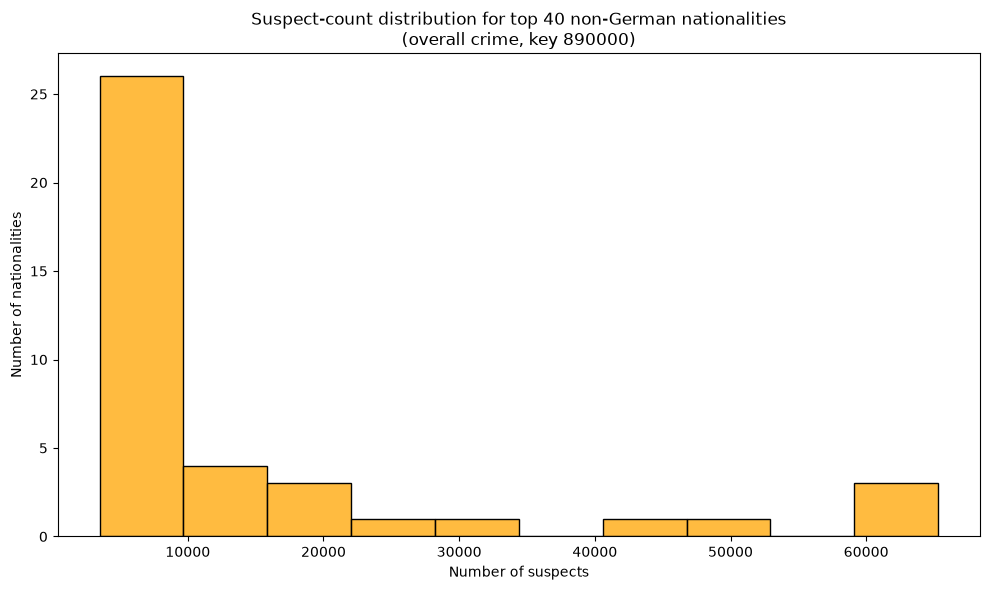

In [281]:
top_non_german = overall[
    (overall['nationality'] != 'Germany') & (overall['suspects'] > 0) # filter out germany because its absolute count would dominate the scale
].nlargest(HIST_TOP_N, 'suspects')

plt.figure(figsize=(10, 6))
sns.histplot(data=top_non_german, x='suspects', bins=10, color=PLOT_COLOR)
plt.xlabel('Number of suspects')
plt.ylabel('Number of nationalities')
plt.title(
    f'Suspect-count distribution for top {HIST_TOP_N} non-German nationalities\n'
    f'(overall crime, key {OVERALL_KEY})'
)
plt.tight_layout()
plt.show()

**Observation:**  

Right-skewed: 
- most of these nationalities have fewer suspects 
- a few groups are much larger



### Count plot: nationalities present per offence group

#### **Question:** How many nationalities appear (with at least 1 suspect) in each selected offence group?



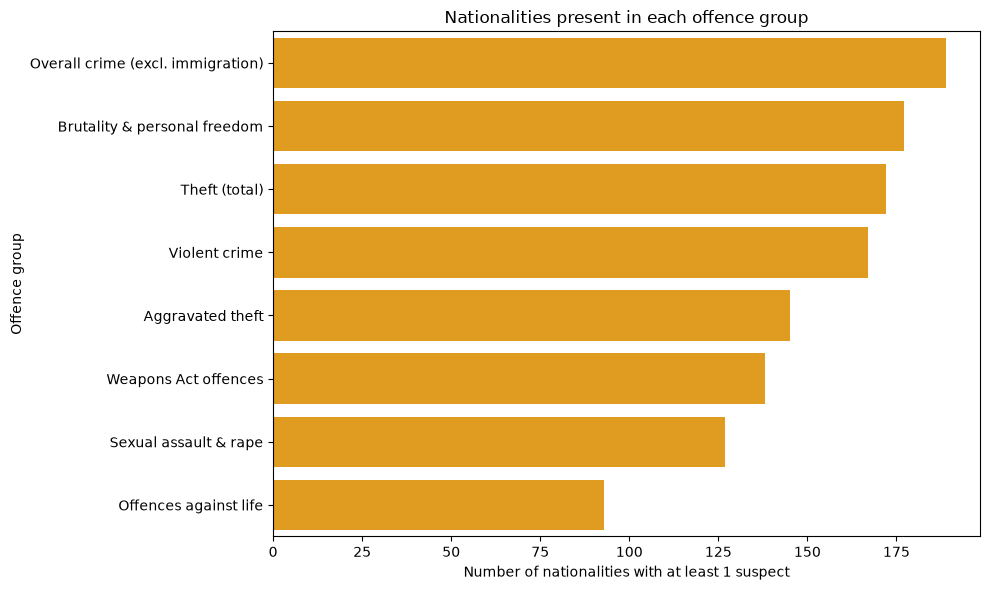

In [282]:
pos_by_offence = crimes_long_df[crimes_long_df['suspects'] > 0].copy()
pos_by_offence['offence_short'] = pos_by_offence['offence'].str.slice(0, 45)

plt.figure(figsize=(10, 6))
sns.countplot(
    data=pos_by_offence,
    y='offence_short',
    order=pos_by_offence['offence_short'].value_counts().index,
    color=PLOT_COLOR,
)
plt.xlabel('Number of nationalities with at least 1 suspect')
plt.ylabel('Offence group')
plt.title('Nationalities present in each offence group')
plt.tight_layout()
plt.show()



**Observation:**  

- broader offence totals involve more nationalities 
- rarer groups (e.g. offences against life) involve fewer



### Discuss the distribution(s) of your variable(s) of interest. Were there any unusual points? Did you need to perform any transformations?

- The suspect counts among top non-German nationalities are right-skewed.
- Most of those nationalities have fewer suspects; a few groups are much larger.
- The count plot shows that rarer offence groups involve fewer nationalities than broad totals.
- Germany was left out of the histogram so it would not dominate the scale (making the other nationalities almost unnoticeable)
- No scale transformations (log) were needed for these univariate plots.

### Of the features you investigated, were there any unusual distributions? Did you perform any operations on the data to tidy, adjust, or change the form of the data? If so, why did you do this?

- I melted the nationality table to long form so nationality could be plotted as a variable.
- I limited the analysis to eight offence aggregates that were already summed up (including sexual assault & rape).
- The key column (Schlüssel) is kept as strings because some keys contain *s (wildcards) and dashes.
- "Ungeklärt" (unknown) and "Ohne Angabe" (not specified) were merged to match Destatis.
- Destatis rows with missing population and footer rows were dropped.
- Short English offence labels were mapped from the selected keys; German names kept as offence_de.


---

## Bivariate Exploration

Population-adjusted rates for the top `TOP_N` nationalities by **absolute** suspects (includes Germany; Unknown/Stateless is excluded): scatter (population vs rate), box plot (rates by offence), and heatmap (nationality vs offence).

Scatter uses overall crime. Box and heatmap use specific offence groups only so the overall group total does not flatten the rest.



### Prepare rate tables



In [283]:
# Population lookup: Destatis 12411 approx. age 8+ (includes Germany)
exclude_nationals = {'Unknown / Not specified', 'Stateless', 'Total'}

pop_lookup = per_country_df[['citizenship', 'population']].rename(
    columns={'citizenship': 'nationality'}
)

rates_long_df = crimes_long_df.merge(pop_lookup, on='nationality', how='inner')
rates_long_df = rates_long_df[~rates_long_df['nationality'].isin(exclude_nationals)].copy()
rates_long_df['suspects_per_100k'] = (
    rates_long_df['suspects'] / rates_long_df['population'] * 100_000
)
rates_long_df['offence_short'] = rates_long_df['offence'].str.slice(0, 35)

rates_overall = rates_long_df[rates_long_df['key'] == OVERALL_KEY].copy()
top_abs_rates = rates_overall.nlargest(TOP_N, 'suspects').copy()
focus_nats = top_abs_rates['nationality']
focus_rates = rates_long_df[rates_long_df['nationality'].isin(focus_nats)].copy()
# Specific offence groups only — overall dwarfs the y-scale in box/heatmap/facet/cluster
focus_rates_detail = focus_rates[focus_rates['key'] != OVERALL_KEY].copy()

print(f'Top {TOP_N} by absolute suspects (used in rate plots):')
print(
    top_abs_rates[['nationality', 'suspects', 'population', 'suspects_per_100k']]
    .to_string(index=False) # hide the index in the table print 
)



Top 15 by absolute suspects (used in rate plots):
              nationality  suspects  population  suspects_per_100k
                  Germany   1230432  66004511.0        1864.163496
                  Romania     65299    689813.0        9466.188663
                   Syrian     62915    758598.5        8293.583496
                   Turkey     62143   1368023.5        4542.538926
                  Ukraine     48440    984719.5        4919.167336
                   Poland     45381    685697.0        6618.229335
 Afghanistan, Republic of     30304    354399.0        8550.814195
                 Bulgaria     27310    323241.0        8448.804452
                    Italy     18774    546528.0        3435.139645
                   Serbia     18544    235211.0        7883.985018
                     Iraq     17734    202767.0        8745.999102
                   Kosovo     13318    282491.0        4714.486479
                  Croatia     10226    360650.0        2835.436018
       Russi

### Scatter: population vs rate

#### **Question:** Among the citizenships with the most absolute suspects, how does population size relate to the suspect rate?



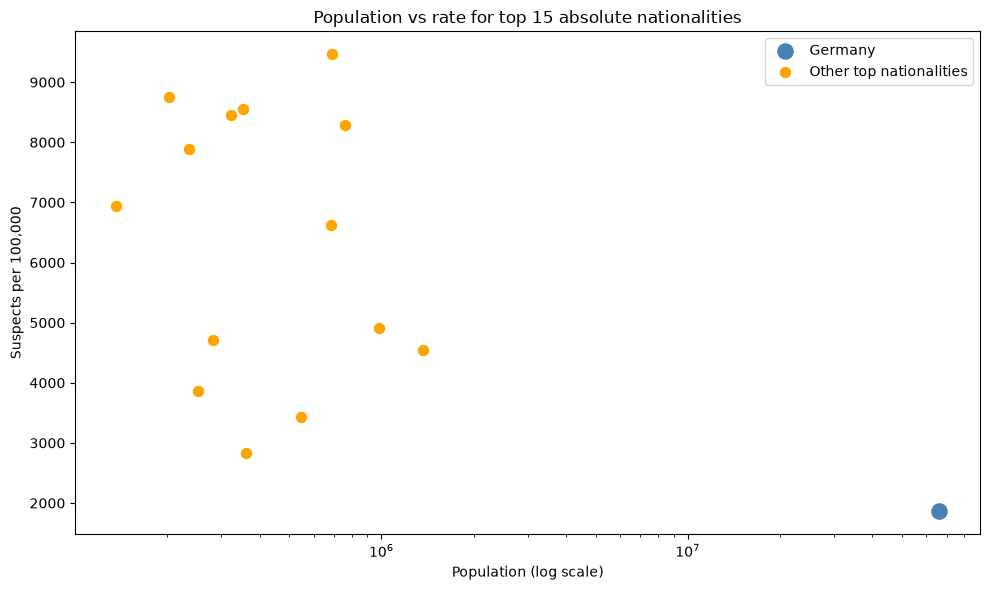

In [284]:
plt.figure(figsize=(10, 6))

de = top_abs_rates[top_abs_rates['nationality'] == 'Germany']
if len(de): # plot Germany with a different color
    plt.scatter(
        de['population'], de['suspects_per_100k'],
        s=120, c=SECONDARY_COLOR, zorder=5,
        label='Germany' # add a little legend for Germany
    )
    plt.legend()

sns.scatterplot(
    data=top_abs_rates,
    x='population',
    y='suspects_per_100k',
    color=PLOT_COLOR,
    s=80,
    label='Other top nationalities' # add the other nationalities to the legend
)

plt.xscale('log')
plt.xlabel('Population (log scale)')
plt.ylabel('Suspects per 100,000')
plt.title(f'Population vs rate for top {TOP_N} absolute nationalities')
plt.tight_layout()
plt.show()



**Observation:**  
- Germany has a very large population and a comparatively lower rate among this set
- Ranking by rate differs significantly from absolute counts



### Box plot: rates by offence

#### **Question:** How do per-100k rates vary across offence groups for these nationalities?



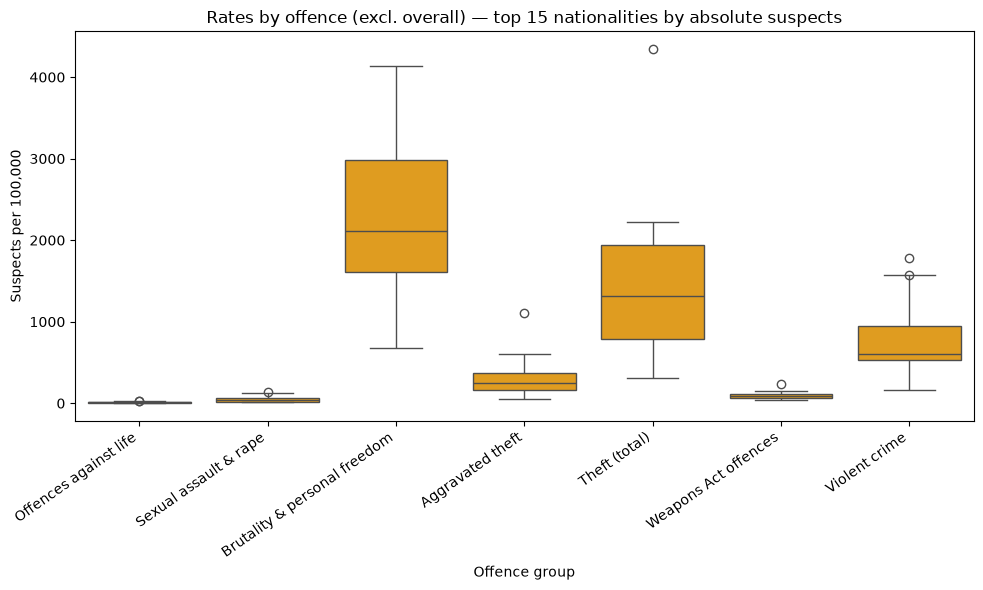

In [285]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=focus_rates_detail,
    x='offence_short',
    y='suspects_per_100k',
    color=PLOT_COLOR,
)
plt.xticks(rotation=35, ha='right')
plt.xlabel('Offence group')
plt.ylabel('Suspects per 100,000')
plt.title(
    f'Rates by offence (excl. overall) — top {TOP_N} '
    f'nationalities by absolute suspects'
)
plt.tight_layout()
plt.show()



**Observation:**  

- Rate levels differ by offence type
- Some groups show wider spread across nationalities than others



### Heatmap: nationality × offence (per 100k)

**Question:** For each top nationality, how do rates compare across the selected offence groups?



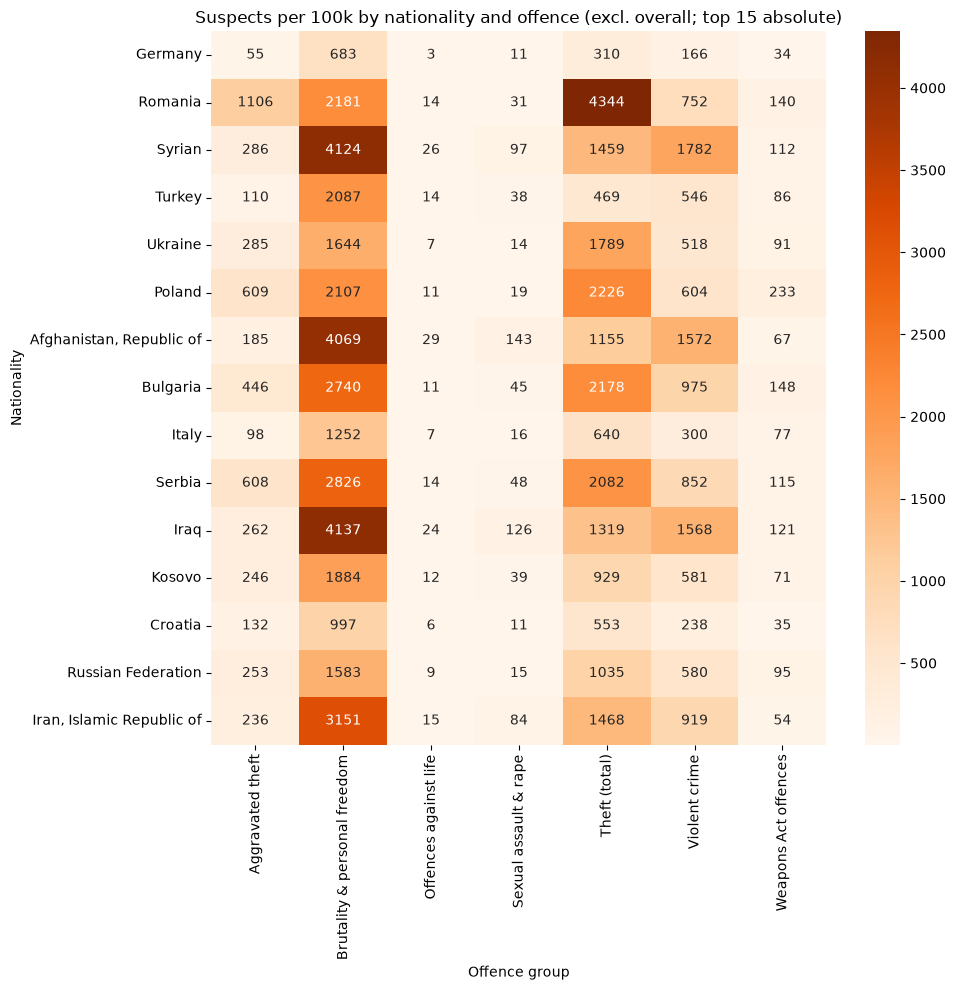

In [286]:
heat_piv = focus_rates_detail.pivot_table(
    index='nationality',
    columns='offence_short',
    values='suspects_per_100k',
    aggfunc='mean',
).reindex(top_abs_rates['nationality'])

plt.figure(figsize=(10, 10))
sns.heatmap(heat_piv, cmap='Oranges', annot=True, fmt='.0f')
plt.title(
    f'Suspects per 100k by nationality and offence '
    f'(excl. overall; top {TOP_N} absolute)'
)
plt.xlabel('Offence group')
plt.ylabel('Nationality')
plt.tight_layout()
plt.show()



**Observation:**  
- Patterns are not uniform: a nationality high for one offence is not automatically high for the others
- Iraqis, Syrians, and Afghans have very high rates for offences involving brutality (over 4k per 100k)
- For offences against life Afghans are highest (~29 per 100k), about 10× Germany (~3 per 100k); Syrians (~26 per 100k) and Iraqis (~24 per 100k) are next
- Romanians have a very high theft rate (over 4k per 100k)

### Talk about some of the relationships you observed in this part of the investigation. How did the feature(s) of interest vary with other features in the dataset?

- Absolute leaders are not the same as rate leaders: Germany dominates absolute counts (natural with a very large population) but not per-100k rates.
- Iraqis, Syrians, and Afghans show very high rates for offences involving brutality (over 4k per 100k)
- Romanians show a very high rate for thefts (over 4k per 100k)

### Did you observe any interesting relationships between the other features (not the main feature(s) of interest)?

- Heatmap cells show offence-specific differences that a single overall rate would hide.



---

## Multivariate Exploration

Same rate tables, now with offence and nationality together: a facet plot across offence groups, then a clustered bar chart for the top `CLUSTER_TOP_N` absolute leaders.



### Facet: rates by offence for top absolute nationalities

**Question:** Does the nationality ranking by rate stay similar across offence groups?



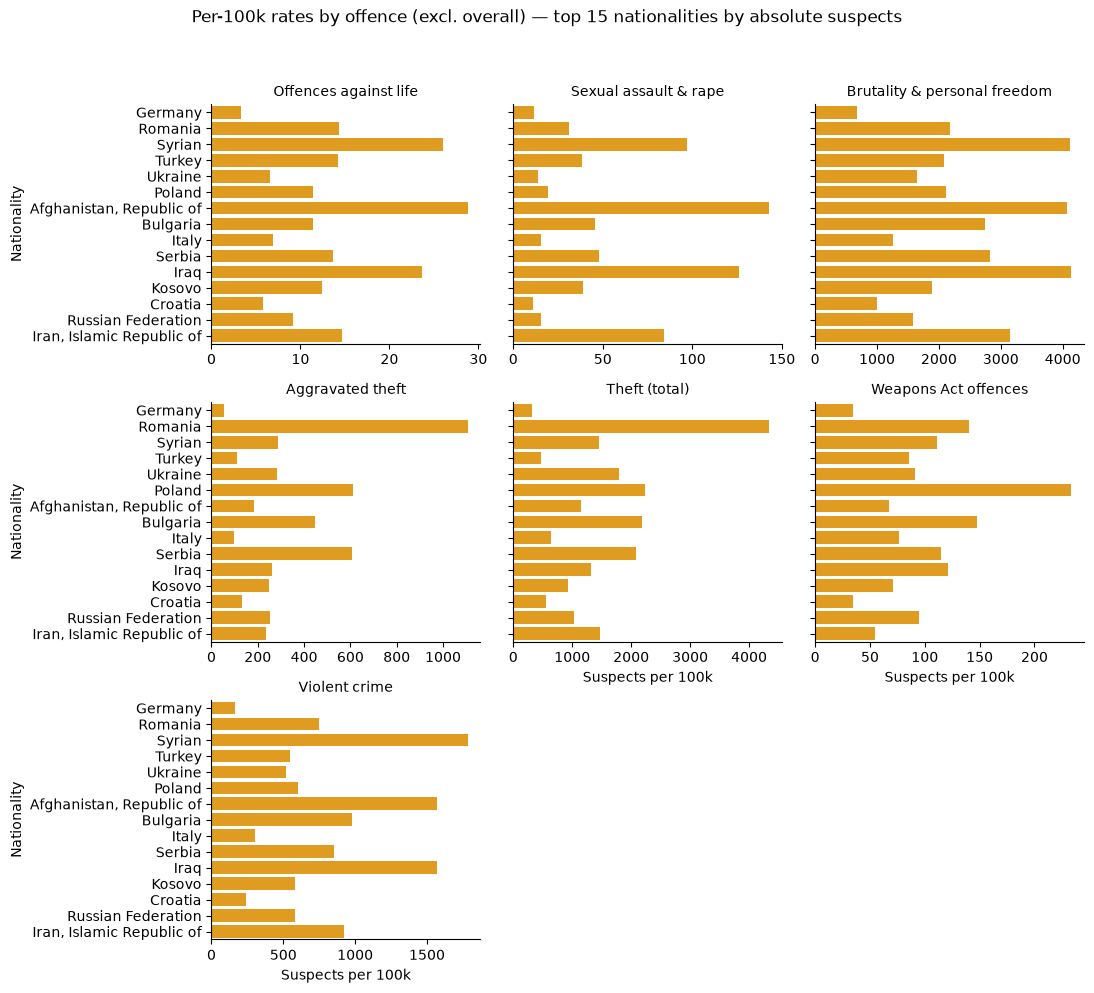

In [287]:
facet_df = focus_rates_detail.copy()
facet_df['offence_facet'] = (
    facet_df['offence'].str.slice(0, 28)
)

g = sns.FacetGrid(
    facet_df,
    col='offence_facet',
    col_wrap=3,
    sharex=False,
    sharey=True,
    height=3.2,
    aspect=1.15,
)
g.map_dataframe(
    sns.barplot,
    x='suspects_per_100k',
    y='nationality',
    color=PLOT_COLOR,
    errorbar=None,
    order=list(top_abs_rates['nationality']),
)
g.set_axis_labels('Suspects per 100k', 'Nationality')
g.set_titles(col_template='{col_name}')
g.figure.suptitle(
    f'Per-100k rates by offence (excl. overall) — '
    f'top {TOP_N} nationalities by absolute suspects',
    y=1.03,
)
plt.tight_layout()
plt.show()



**Observation:**  
- Rank order shifts somewhat by offence
- Germany stays relatively low on the rate scale across facets.



### Clustered bars: top nationalities × offence (per 100k)

**Question:** Focusing on `CLUSTER_TOP_N` absolute leaders, how do rates compare side by side by offence?

Overall crime is left out. The first plot shows all remaining offence groups together; a second plot zooms into the three lower-volume ones that get flattened on that shared scale.



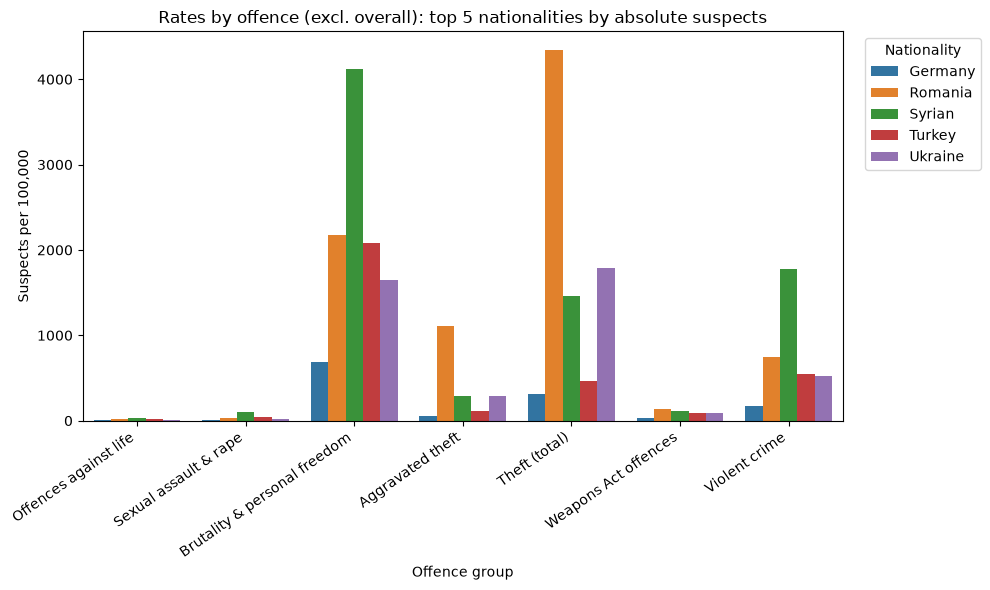

In [288]:
top_cluster = top_abs_rates.head(CLUSTER_TOP_N)['nationality']
cluster_df = focus_rates_detail[
    focus_rates_detail['nationality'].isin(top_cluster)
].copy()
cluster_df['offence_label'] = cluster_df['offence'].str.slice(0, 30)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=cluster_df,
    x='offence_label',
    y='suspects_per_100k',
    hue='nationality',
    hue_order=list(top_cluster),
    errorbar=None,
)
plt.xticks(rotation=35, ha='right')
plt.xlabel('Offence group')
plt.ylabel('Suspects per 100,000')
plt.title(
    f'Rates by offence (excl. overall): top {CLUSTER_TOP_N} '
    f'nationalities by absolute suspects'
)
plt.legend(title='Nationality', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()



**Observation:**  
- Syrian rates sit at the top for both brutality & personal freedom and violent crime (two related groups of offences).
- Romania stands out clearly on both theft totals and aggravated theft (also two related groups).
- Germany stays lowest of these five on most of the high-volume groups.
- Offences against life, sexual assault & rape, and Weapons Act are hard to read here because the y-scale is driven by theft and brutality. That is why the next plot shows only those three.



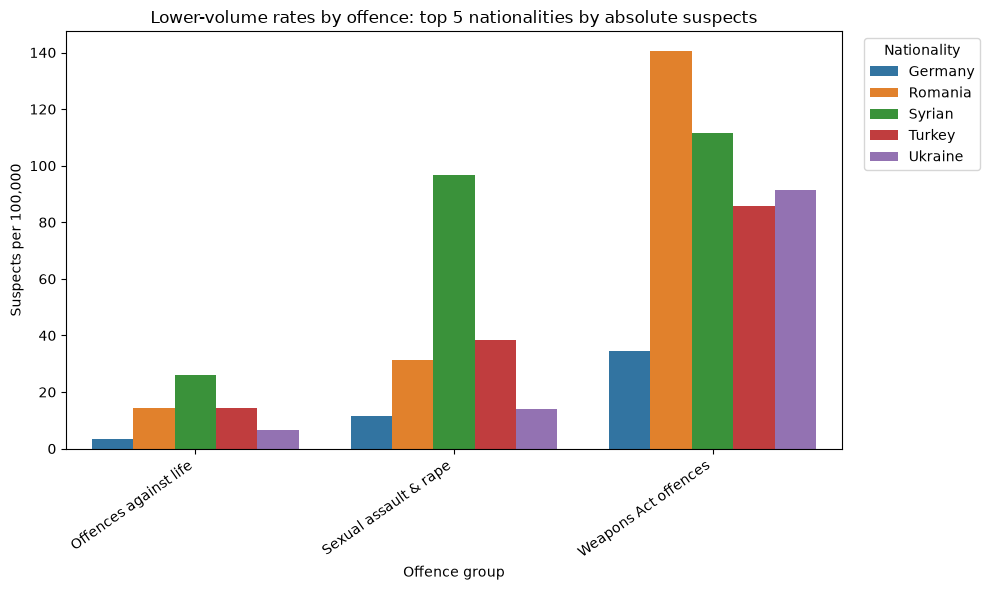

In [289]:
RARE_KEYS = {'000000', '111000', '726200'}  # life, sexual assault & rape, Weapons Act
cluster_rare = cluster_df[cluster_df['key'].isin(RARE_KEYS)].copy()

plt.figure(figsize=(10, 6))
sns.barplot(
    data=cluster_rare,
    x='offence_label',
    y='suspects_per_100k',
    hue='nationality',
    hue_order=list(top_cluster),
    errorbar=None,
)
plt.xticks(rotation=35, ha='right')
plt.xlabel('Offence group')
plt.ylabel('Suspects per 100,000')
plt.title(
    f'Lower-volume rates by offence: top {CLUSTER_TOP_N} '
    f'nationalities by absolute suspects'
)
plt.legend(title='Nationality', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [290]:
# Quick calculation of Syrian sexual assault & rape rate and  Offences against life rate vs German rate
rare_sy_de = cluster_rare.set_index(['key', 'nationality'])['suspects_per_100k']
print(f"Syrian's sexual assault & rape rate is {rare_sy_de.loc[('111000', 'Syrian')] / rare_sy_de.loc[('111000', 'Germany')]:.1f} times German's")
rare_life_de = cluster_rare.set_index(['key', 'nationality'])['suspects_per_100k']
print(f"Syrian's offences against life rate is {rare_life_de.loc[('000000', 'Syrian')] / rare_life_de.loc[('000000', 'Germany')]:.1f} times German's")


Syrian's sexual assault & rape rate is 8.4 times German's
Syrian's offences against life rate is 7.9 times German's


**Observation:**  
- With its own scale, gaps for offences against life, sexual assault & rape, and Weapons Act are easier to see.
- Syria is again highest on sexual assault & rape and offences against life
- Syrian sexual assault & rape rate is about 8.4 times German’s
- Syrian offences against life rate is about 7.9 times German's
- The life bars are smaller overall.


### Talk about some of the relationships you observed in this part of the investigation. Were there features that strengthened each other in terms of looking at your feature(s) of interest?

- Looking at rates one offence group at a time shows that the nationality gaps change by crime type
- Putting nationality, offence, and rate in one clustered bar chart makes the counts-vs-rates contrast easier to see

### Were there any interesting or surprising interactions between features?

- Some nationalities lead clearly on related offence groups (e.g. Syria on brutality and violent crime; Romania on both theft groups)


## Conclusions

### Main findings
- Germans dominate absolute suspect counts, but their rate per 100k is comparatively low
- Ranking by rate differs a lot from ranking by absolute counts, due to most residents having the citizenship of Germany.
- Gaps between nationalities change by offence group. Countries that are high for one crime group are not automatically high for the others.
- Some nationalities lead clearly on related offence groups. Syria leads on brutality and violent crime. Romania leads on both theft-related groups.
- Among the 5 absolute leaders, the Syrian sexual assault & rape rate is about 8.4 times German’s; offences against life about 7.9 times German's.

### How I got there
- I started with absolute counts, then linked a Destatis population file after approximating the youngest age band to 8+ years to look at rates per 100k.
- Compared selected offence groups side by side and left the overall total group out of the detail plots so rarer offence groups would be easier to read and not be near the x axis. 
- For the clustered bars, the low-volume crime groups were still too hard to read on the shared scale, so I added a second plot with only those three low-volume groups for better readability. 


In [291]:
# export the dataframe for part II
focus_rates.to_csv('data/polished_dataset.csv', index=False)
